In [1]:
import numpy as np
from torch.utils.data import Dataset
import torchvision.transforms.v2 as T
from torchvision.io import read_image, ImageReadMode
import matplotlib.pyplot as plt
import zipfile
from pathlib import Path
from urllib.request import urlretrieve

from accuracy_bounds.classificationproblems.utils import wavelet_array_features
from accuracy_bounds.classificationproblems.feasible_sets import feasible_sets_classification_nn
from accuracy_bounds.classificationproblems.kersize_compute import compute_kernel_size_one_hot

---
## Load the data

In [2]:
data_root = Path("data/raw/")
splits_dir = Path("data/splits")
stats_dir = Path("data/stats")
noise_dir = Path("data/noise")

HF_URL = ("https://hf.co/datasets/torchgeo/eurosat/resolve/1ce6f1bfb56db63fd91b6ecc466ea67f2509774c/EuroSAT.zip")
FILENAME = "EuroSAT.zip"
BASE_DIR = Path("EuroSAT")

data_path = data_root / BASE_DIR

seed = 42
img_size = 64

In [3]:
def _download_and_extract(data_path: Path):
    data_path.mkdir(parents=True, exist_ok=True)
    zip_path = data_path / FILENAME

    HF_URL_train_split = "https://huggingface.co/datasets/torchgeo/eurosat/resolve/main/eurosat-train.txt"
    HF_URL_val_split = "https://huggingface.co/datasets/torchgeo/eurosat/resolve/main/eurosat-val.txt"
    HF_URL_test_split = "https://huggingface.co/datasets/torchgeo/eurosat/resolve/main/eurosat-test.txt"

    train_split_path = data_path / "eurosat-train.txt"
    val_split_path = data_path / "eurosat-val.txt"
    test_split_path = data_path / "eurosat-test.txt"
    extract_dir = data_path / BASE_DIR

    if not zip_path.exists():
        print(f"Downloading EuroSAT (~100MB) to {zip_path} ...")
        urlretrieve(HF_URL, zip_path)

    if not train_split_path.exists():
        print("Downloading train split file ...")
        urlretrieve(HF_URL_train_split, train_split_path)

    if not val_split_path.exists():
        print("Downloading val split file ...")
        urlretrieve(HF_URL_val_split, val_split_path)

    if not test_split_path.exists():
        print("Downloading test split file ...")
        urlretrieve(HF_URL_test_split, test_split_path)

    if not extract_dir.exists():
        print(f"Extracting {zip_path} ...")
        with zipfile.ZipFile(zip_path) as zf:
            zf.extractall(extract_dir)

    return extract_dir, {
        "train": train_split_path,
        "val": val_split_path,
        "test": test_split_path,
    }


def _read_split_file(path: Path):
    # Match on the file stem (e.g. "AnnualCrop_1") so the extension doesn't matter.
    with open(path) as f:
        return [Path(line.strip()).stem for line in f if line.strip()]


def build_split_data(data_path: Path):
    extract_dir, split_files = _download_and_extract(data_path)

    # Map file stem -> full path for every extracted image
    jpg_index = {p.stem: p for p in extract_dir.rglob("*.jpg")}
    if not jpg_index:
        raise FileNotFoundError(f"No .jpg files found under {extract_dir}")

    # Class = name of the parent folder (AnnualCrop, Forest, ...)
    classes = sorted({p.parent.name for p in jpg_index.values()})
    class_to_idx = {c: i for i, c in enumerate(classes)}

    split_data = {"classes": classes}
    for subset, split_path in split_files.items():
        stems = _read_split_file(split_path)
        missing = [s for s in stems if s not in jpg_index]
        if missing:
            raise FileNotFoundError(
                f"{len(missing)} files from {split_path.name} not found, e.g. {missing[:3]}"
            )
        split_data[subset] = [
            (str(jpg_index[s]), class_to_idx[jpg_index[s].parent.name]) for s in stems
        ]
        print(f"{subset}: {len(split_data[subset])} samples")

    return split_data


class EuroSATDataset(Dataset):
    def __init__(self, split_data, subset, transform=None):
        assert subset in ("train", "val", "test")
        self.samples = split_data[subset]
        self.classes = split_data["classes"]
        self.transform = transform
        self.subset = subset
        self._clean_labels = [s[1] for s in self.samples]
        self.targets = [s[1] for s in self.samples]

    def __len__(self):
        return len(self.samples)

    @staticmethod
    def read_img(path):
        # (3, H, W) float32 tensor with values in [0, 1]
        return read_image(path, mode=ImageReadMode.RGB).float() / 255.0

    def __getitem__(self, idx):
        path, _ = self.samples[idx]
        img = self.read_img(path)

        if self.transform:
            img = self.transform(img)
        return img, self.targets[idx]

In [4]:
_download_and_extract(data_path)

Extracting data/raw/EuroSAT/EuroSAT.zip ...


(PosixPath('data/raw/EuroSAT/EuroSAT'),
 {'train': PosixPath('data/raw/EuroSAT/eurosat-train.txt'),
  'val': PosixPath('data/raw/EuroSAT/eurosat-val.txt'),
  'test': PosixPath('data/raw/EuroSAT/eurosat-test.txt')})

In [5]:
# number of subprocesses to use for data loading
num_workers = 0
# how many samples per batch to load
batch_size = 32
seed = 42

train_tf = eval_tf = T.Normalize(mean=[0.5,0.5,0.5], std=[0.5,0.5,0.5])

split_data = build_split_data(data_path)

train_data = EuroSATDataset(split_data, "train", transform=train_tf)
val_data   = EuroSATDataset(split_data, "val",   transform=eval_tf)
test_data  = EuroSATDataset(split_data, "test",  transform=eval_tf)

# specify the image classes
classes = ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway',
           'Industrial', 'Pasture', 'PermanentCrop', 'Residential',
           'River', 'SeaLake']

train: 16200 samples
val: 5400 samples
test: 5400 samples


## Average kernel size for one Mickey Mouse image to labels of EuroSAT

In [6]:
from collections import Counter

counts = Counter(test_data.targets)

M = len(test_data.targets)

same_pairs = sum(n * (n - 1) // 2 for n in counts.values())
total_pairs = M * (M - 1) // 2
diff_pairs = total_pairs - same_pairs

average_kersize = 2 * diff_pairs / total_pairs / 2

print(M)
print(counts)
print("Upper accuracy bound:", 1 - 0.5 * average_kersize)

5400
Counter({9: 609, 1: 608, 0: 596, 2: 573, 7: 554, 6: 538, 8: 529, 4: 501, 3: 496, 5: 396})
Upper accuracy bound: 0.5505704760140766


## Average kernel size on training set

In [7]:
train_images = []
train_labels = []

for img, label in train_data:
    train_images.append(img.numpy())   # (3, 64, 64)
    train_labels.append(label)

train_images = np.stack(train_images)
train_labels = np.array(train_labels)

print(train_images.shape)   # (16200, 3, 64, 64)
print(train_labels.shape)   # (16200,)

(16200, 3, 64, 64)
(16200,)


### Get wavelet features on training set

In [8]:
train_features = wavelet_array_features(train_images, wavelet="haar")

### Compute average kernel size from feasible sets with nearest neighbors and wavelet features induced pseudometric

In [9]:
# N_max is maximum number of neighbors to consider for feasible sets, qx is the quantile for distance threshold
feas = feasible_sets_classification_nn(train_features, train_labels, N_max=200,qx=0.09)
tau_x= feas["tau_x"]
feasible_sets= feas["feasible_sets"]
D_prime = feas["D_prime"]
distances = feas["distances"]
indices = feas["indices"]

average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(feasible_sets)
print("average_kersize on train set: ", average_kersize)
print("Lower accuracy bound:", 1 - average_kersize)
print("Upper accuracy bound:", 1 - 0.5 * average_kersize)
print("D':", D_prime)
print("tau_x:", tau_x)
print("M':", M_prime)
print("Nk:", Nk_stats)

average_kersize on train set:  0.02222258431045058
Lower accuracy bound: 0.9777774156895495
Upper accuracy bound: 0.9888887078447747
D': []
tau_x: 2.4434842586517336
M': 89750
Nk: (1, 5.540123456790123, 1.0, 201)


In [10]:
print("average_kersize on train set: ", average_kersize)
print("Lower accuracy bound:", 1 - average_kersize)
print("Upper accuracy bound:", 1 - 0.5 * average_kersize)

average_kersize on train set:  0.02222258431045058
Lower accuracy bound: 0.9777774156895495
Upper accuracy bound: 0.9888887078447747


### Ablation on maximum number of nearest neighbors and quantiles

In [11]:
train_result_dict = {}

N_list = sorted([10, 20, 30, 40, 50, 100, 200, 300, 450, 750, 1000, 2000], reverse=True)
qx_list = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

neighbor_stats = None # go though N_max in reverse order to only compute the larges N once

for N_id, N_max in enumerate(N_list):
    train_result_dict[N_max] ={}

    for qx_id, qx in enumerate(qx_list): 
        train_result_dict[N_max][qx] = {"avg_ker_size": None, 
                                  "tau_x": None,
                                  "N_k_stats": None}

        print(f"qx [{qx_id+1}/{len(qx_list)}]: {qx}   |   N_max [{N_id+1}/{len(N_list)}]: {N_max} ...           ", end="\r")
        feas = feasible_sets_classification_nn(train_features, train_labels, 
                                               N_max=N_max,
                                               qx=qx,
                                               neighbor_stats=neighbor_stats)
        
        tau_x= feas["tau_x"]
        feasible_sets= feas["feasible_sets"]
        D_prime = feas["D_prime"]

        if neighbor_stats is None: 
            neighbor_stats = {"distances": feas["distances"],
                              "indices": feas["indices"]}

        average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(feasible_sets)
        train_result_dict[N_max][qx]["avg_ker_size"] = average_kersize
        train_result_dict[N_max][qx]["tau_x"] = tau_x
        train_result_dict[N_max][qx]["N_k_stats"] = Nk_stats

## Average kernel size on test set

In [12]:
test_images = []
test_labels = []

for img, label in test_data:
    test_images.append(img.numpy())   # (3,64,64)
    test_labels.append(label)

test_images = np.stack(test_images)
test_labels = np.array(test_labels)

print(test_images.shape)   # (5400,3,64,64)
print(test_labels.shape)   # (5400,)

(5400, 3, 64, 64)
(5400,)


### Get wavelet features on test set

In [13]:
test_features = wavelet_array_features(test_images, wavelet="haar")

### Compute average kernel size from feasible sets with nearest neighbors and wavelet features induced pseudometric

In [14]:
feas = feasible_sets_classification_nn(test_features, test_labels, N_max=200,qx=0.09)
tau_x= feas["tau_x"]
feasible_sets= feas["feasible_sets"]
D_prime = feas["D_prime"]
distances = feas["distances"]
indices = feas["indices"]

average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(feasible_sets)
print("average_kersize on test set: ", average_kersize)
print("Lower accuracy bound:", 1 - average_kersize)
print("Upper accuracy bound:", 1 - 0.5 * average_kersize)
print("D':", D_prime)
print("tau_x:", tau_x)
print("M':", M_prime)
print("Nk:", Nk_stats)

average_kersize on test set:  0.031106281434211912
Lower accuracy bound: 0.9688937185657881
Upper accuracy bound: 0.984446859282894
D': []
tau_x: 2.704906494617462
M': 14976
Nk: (1, 2.7733333333333334, 1.0, 92)


### Best accuracy on contructed test dataset

In [15]:
def compute_accuracy_star(feasible_sets):
    """Compute Acc_* for a collection of feasible sets."""
    return sum(
        max(np.bincount(Y.astype(int)))
        for Y in feasible_sets if len(Y)
    ) / sum(len(Y) for Y in feasible_sets)


Acc = compute_accuracy_star(feasible_sets)
print("Best accuracy on constructed test dataset", Acc)

Best accuracy on constructed test dataset 0.9793669871794872


### Ablation on quantiles and maximum number of nearest neighbors

In [16]:
test_result_dict = {}

N_list = sorted([10, 20, 30, 40, 50, 100, 200, 300, 450, 750, 1000, 2000], reverse=True)
qx_list = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

neighbor_stats = None # go though N_max in reverse order to only compute the larges N once

for N_id, N_max in enumerate(N_list):
    test_result_dict[N_max] ={}

    for qx_id, qx in enumerate(qx_list): 
        test_result_dict[N_max][qx] = {"avg_ker_size": None, 
                                  "tau_x": None,
                                  "N_k_stats": None}

        print(f"qx [{qx_id+1}/{len(qx_list)}]: {qx}   |   N_max [{N_id+1}/{len(N_list)}]: {N_max} ...           ", end="\r")
        feas = feasible_sets_classification_nn(test_features, test_labels, 
                                               N_max=N_max,
                                               qx=qx,
                                               neighbor_stats=neighbor_stats)
        
        tau_x= feas["tau_x"]
        feasible_sets= feas["feasible_sets"]
        D_prime = feas["D_prime"]

        if neighbor_stats is None: 
            neighbor_stats = {"distances": feas["distances"],
                              "indices": feas["indices"]}

        average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(feasible_sets)
        test_result_dict[N_max][qx]["avg_ker_size"] = average_kersize
        test_result_dict[N_max][qx]["tau_x"] = tau_x
        test_result_dict[N_max][qx]["N_k_stats"] = Nk_stats

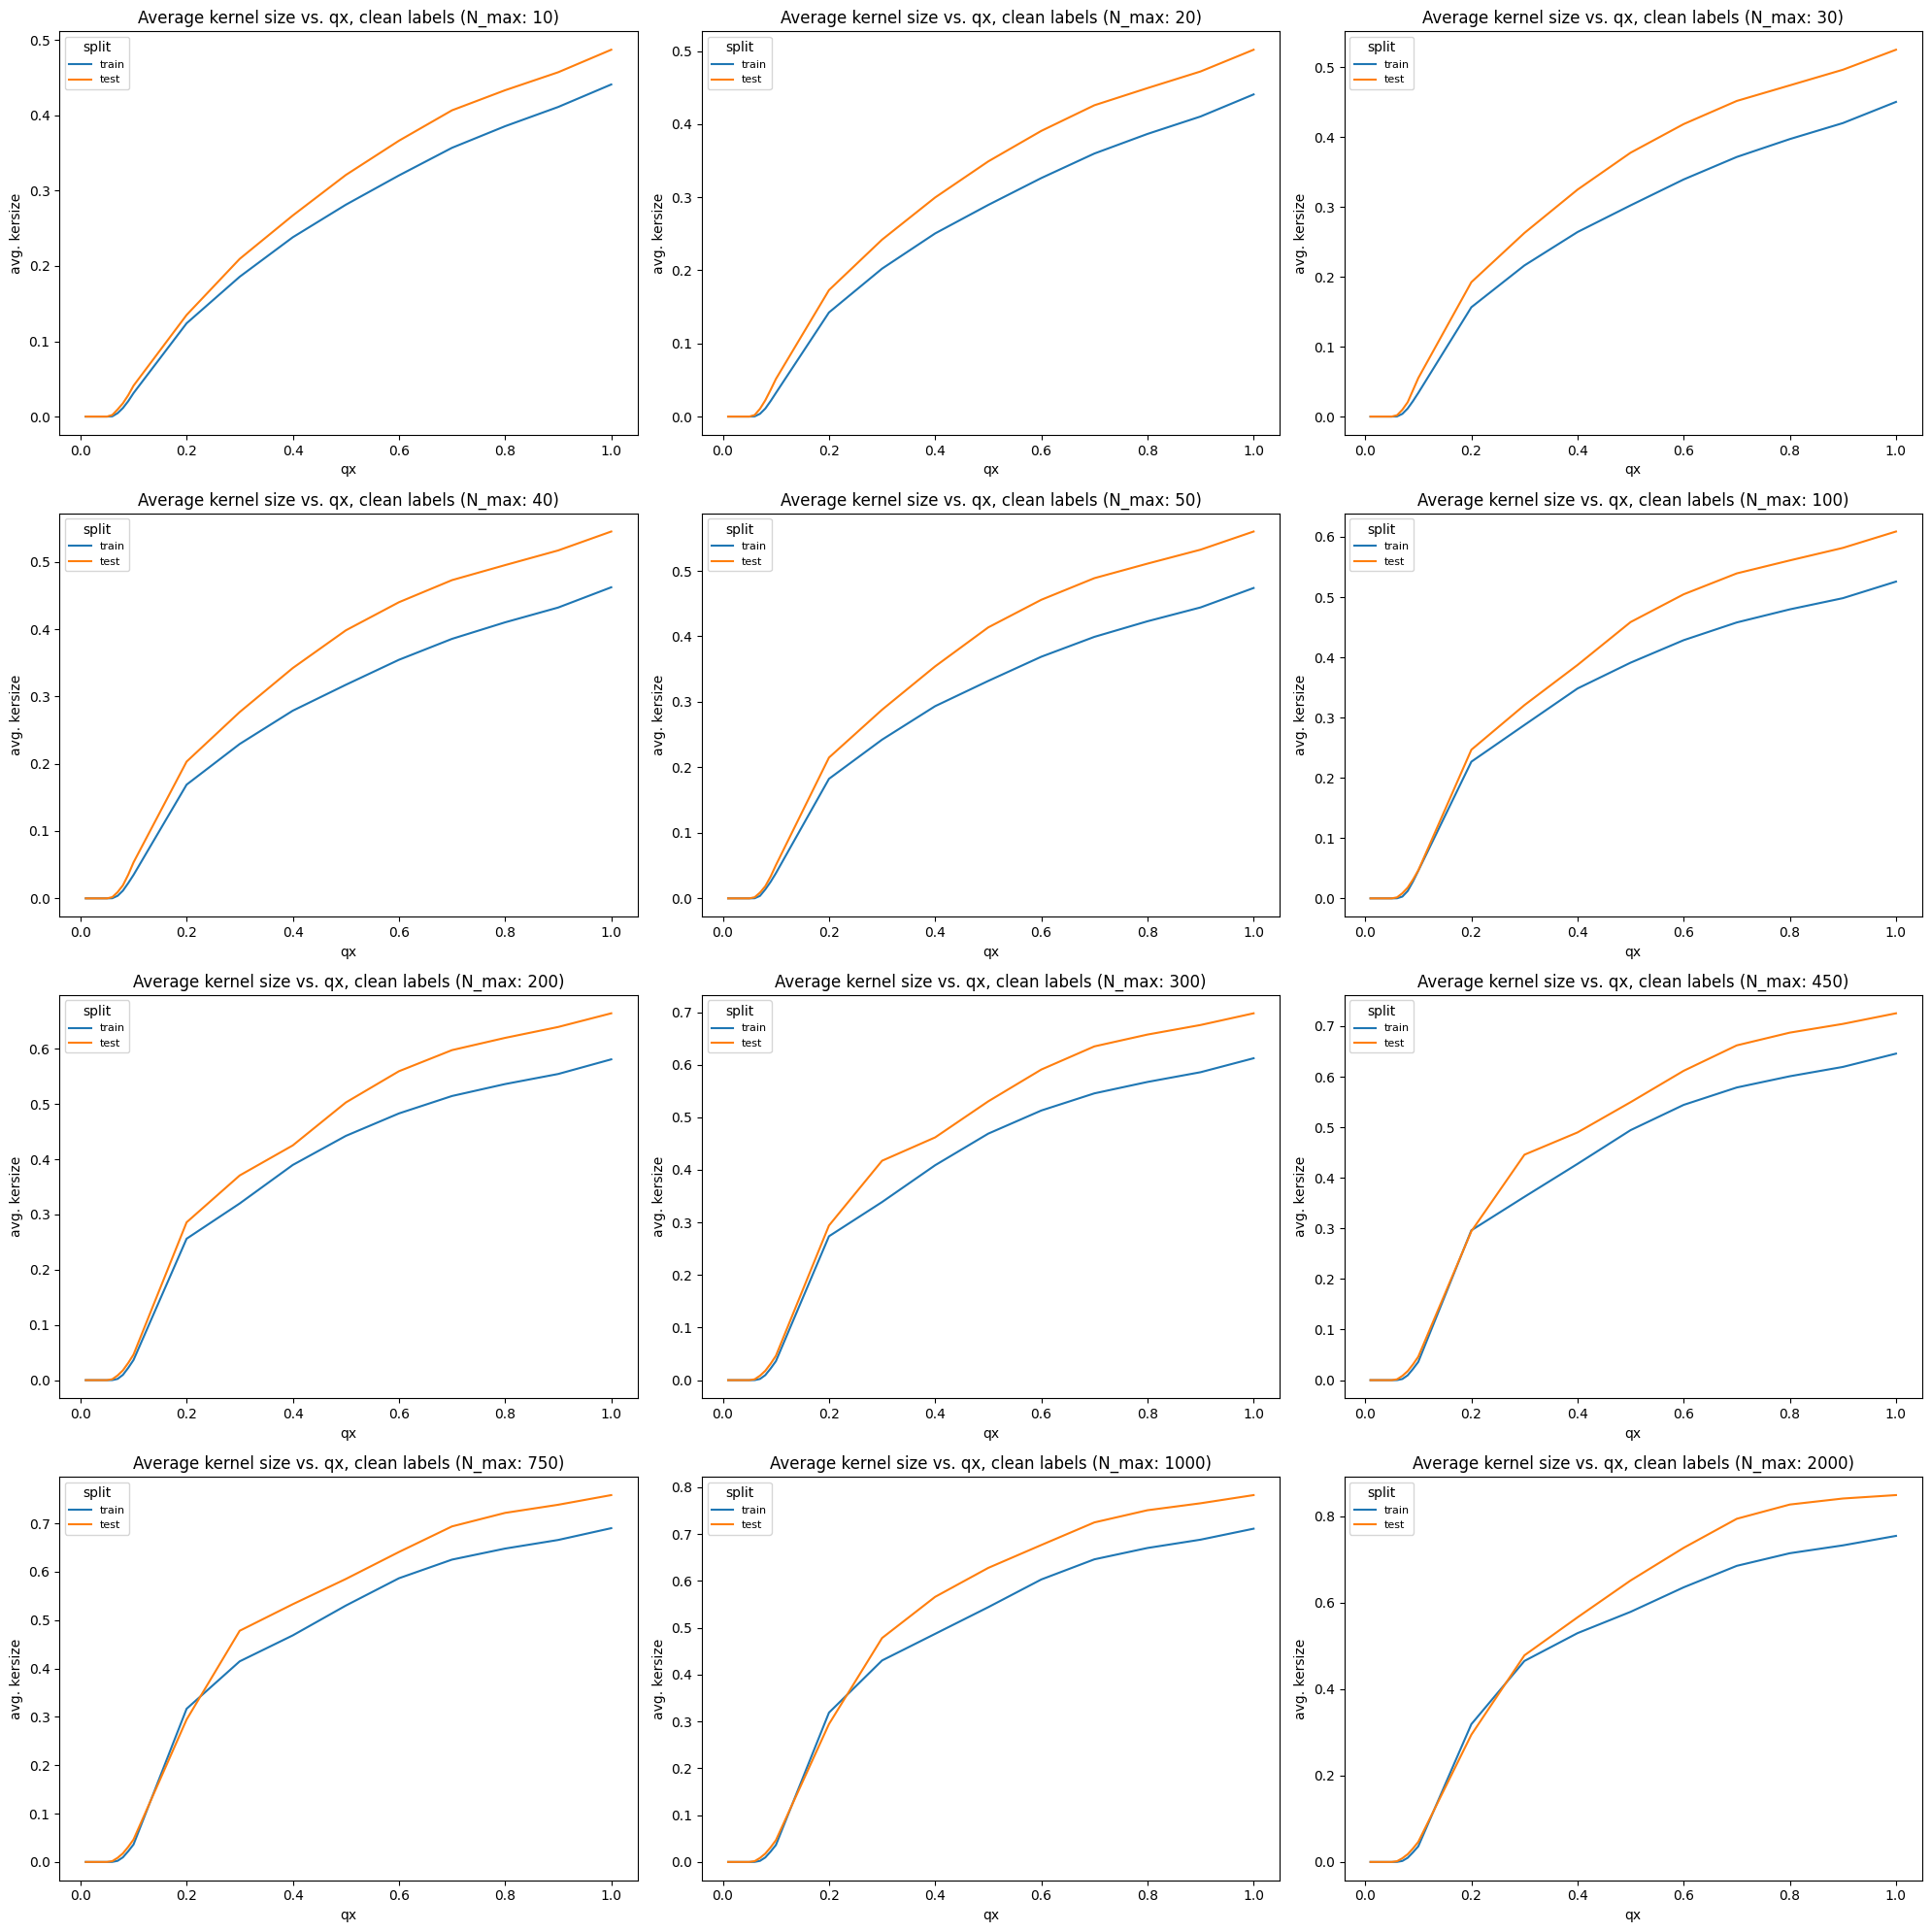

In [17]:
n_max_list = sorted(train_result_dict)
qx_values = list(train_result_dict[n_max_list[0]])

num_cols = 3
fig, ax = plt.subplots(int(np.ceil(len(n_max_list) / num_cols)), num_cols,
                       figsize=(20, 5 * int(np.ceil(len(n_max_list) / num_cols))), squeeze=False)
for a, n in zip(ax.flat, n_max_list):
    for name, d in [("train", train_result_dict), ("test", test_result_dict)]:
        a.plot(qx_values, [d[n][qx]["avg_ker_size"] for qx in qx_values], label=name)
    a.set_title(f"Average kernel size vs. qx, clean labels (N_max: {n})")
    a.set_xlabel("qx")
    a.set_ylabel("avg. kersize")
    a.legend(fontsize=8, title="split")
for a in ax.flat[len(n_max_list):]:
    a.axis("off")
plt.tight_layout()
plt.show()

## Visualize Feasible Sets

In [18]:
# generate feasible sets on test set for visualization
# N_max is maximum number of neighbors to consider for feasible sets, qx is the quantile for distance threshold
feas = feasible_sets_classification_nn(test_features, test_labels, test_images, N_max=200,qx=0.09, ext_d = True)
tau_x= feas["tau_x"]
feasible_sets= feas["feasible_sets"]
D_prime = feas["D_prime"]
distances = feas["distances"]
indices = feas["indices"]

tau_x: 2.704906494617462


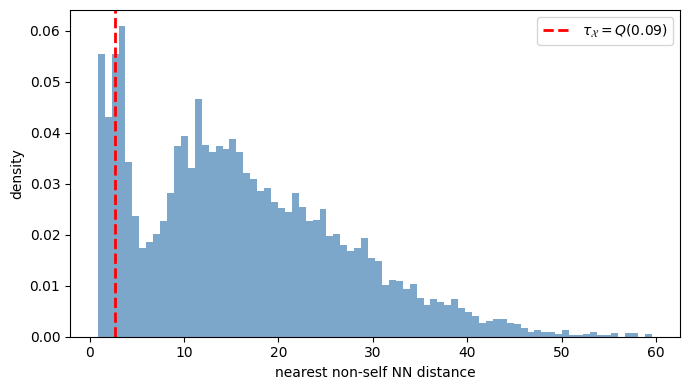

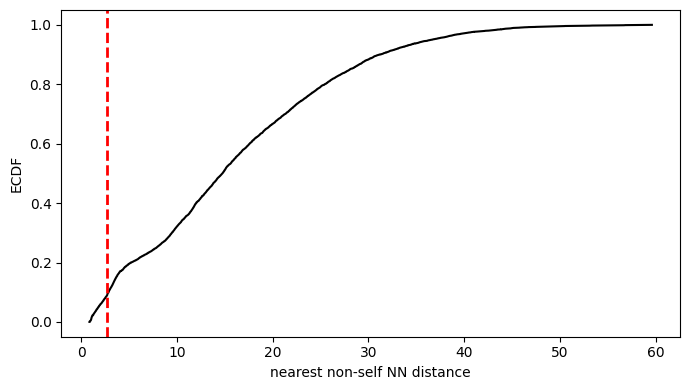

In [19]:


nearest_dist = distances[:, 1]  # nearest non-self distance
tau_x = np.quantile(nearest_dist, 0.09)

print("tau_x:", tau_x)

# --- histogram (log-scale on y often helps) ---
plt.figure(figsize=(7,4))
plt.hist(nearest_dist, bins=80, density=True, alpha=0.7, color="steelblue")
plt.axvline(tau_x, color="red", linestyle="--", linewidth=2,
            label=fr"$\tau_\mathcal{{X}} = Q({0.09})$")
plt.xlabel("nearest non-self NN distance")
plt.ylabel("density")
plt.legend()
plt.tight_layout()
plt.show()

# --- ECDF plot (often more informative than histograms) ---
x = np.sort(nearest_dist)
y = np.arange(1, len(x)+1) / len(x)

plt.figure(figsize=(7,4))
plt.plot(x, y, color="black")
plt.axvline(tau_x, color="red", linestyle="--", linewidth=2)
plt.xlabel("nearest non-self NN distance")
plt.ylabel("ECDF")
plt.tight_layout()
plt.show()


In [20]:


_MEAN = np.array([0.5, 0.5, 0.5], dtype=np.float32)[:, None, None]
_STD  = np.array([0.5, 0.5, 0.5], dtype=np.float32)[:, None, None]

def unnormalize(img):
    """
    Undo EuroSAT normalization.

    Parameters
    ----------
    img : ndarray, shape (3, H, W)

    Returns
    -------
    ndarray, shape (3, H, W), values in [0,1]
    """
    img = img.copy()
    img = img * _STD + _MEAN
    return np.clip(img, 0.0, 1.0)

def show_neighbor_pairs(test_images, indices, distances, tau_x, num_pairs=5, labels=None):
    """
    Visualize pairs of images that are nearest neighbors within tau_x.
    If `labels` is provided (a list/array of class names or label indices,
    one per image in test_images), it's included in each subplot title.
    """
    pairs = []
    # loop over anchor images
    for i in range(len(test_images)):
        for idx, dist in zip(indices[i], distances[i]):
            if dist <= tau_x and i != idx:
                pairs.append((i, idx, dist))
    # plot pairs
    fig, axes = plt.subplots(num_pairs, 2, figsize=(6, 3 * num_pairs))
    if num_pairs == 1:
        axes = np.expand_dims(axes, 0)
    np.random.shuffle(pairs)
    pairs = pairs[:min(len(pairs), num_pairs)]
    for row, (i, j, dist) in enumerate(pairs):
        img1 = np.transpose(unnormalize(test_images[i]), (1, 2, 0))
        img2 = np.transpose(unnormalize(test_images[j]), (1, 2, 0))
        title1 = f"Anchor i={i}"
        title2 = f"Neighbor j={j}, d={dist:.3f}"
        if labels is not None:
            title1 += f"\nlabel={labels[i]}"
            title2 += f"\nlabel={labels[j]}"
        axes[row, 0].imshow(img1)
        axes[row, 0].set_title(title1)
        axes[row, 0].axis("off")
        axes[row, 1].imshow(img2)
        axes[row, 1].set_title(title2)
        axes[row, 1].axis("off")
    plt.tight_layout()
    plt.show()


def show_class_neighbor_grid(test_images, indices, distances, labels, num_neighbors=10, classes=None):
    """
    Build a grid with one row per class. For each class, pick a random
    anchor image from that class and plot its `num_neighbors` closest
    neighbors (columns) based on precomputed `indices`/`distances`.

    Parameters
    ----------
    test_images : array-like, shape (N, 3, H, W)
    indices : array-like, shape (N, k) - neighbor indices per image (e.g. from a NN search)
    distances : array-like, shape (N, k) - corresponding distances
    labels : array-like, shape (N,) - class label (int or str) per image, used to
             pick one random anchor per class
    num_neighbors : int, number of closest neighbors to show per row (default 10)
    classes : optional list mapping label index -> class name, used for row titles
    """
    num_neighbors += 1 # first image should be original 
    labels = np.asarray(labels)
    unique_classes = np.unique(labels)
    num_classes = len(unique_classes)

    fig, axes = plt.subplots(num_classes, num_neighbors,
                              figsize=(2 * num_neighbors, 2 * num_classes))
    if num_classes == 1:
        axes = np.expand_dims(axes, 0)
    if num_neighbors == 1:
        axes = np.expand_dims(axes, 1)

    for row, cls in enumerate(unique_classes):
        # pick a random anchor belonging to this class
        cls_pool = np.where(labels == cls)[0]
        anchor = np.random.choice(cls_pool)

        # get neighbors sorted by distance, excluding the anchor itself
        neighbor_idx = np.array(indices[anchor])
        neighbor_dist = np.array(distances[anchor])
        order = np.argsort(neighbor_dist)
        neighbor_idx = neighbor_idx[order]
        neighbor_dist = neighbor_dist[order]

        neighbor_idx = neighbor_idx[:num_neighbors]
        neighbor_dist = neighbor_dist[:num_neighbors]

        class_name = classes[cls] if classes is not None else cls

        for col in range(num_neighbors):
            ax = axes[row, col]
            if col < len(neighbor_idx):
                j = neighbor_idx[col]
                dist = neighbor_dist[col]
                img = np.transpose(unnormalize(test_images[j]), (1, 2, 0))
                ax.imshow(img)
                title = f"d={dist:.3f}"
                if col == 0:
                    title = f"class={class_name}\nanchor={anchor}\n" + title
                ax.set_title(title, fontsize=8)
            ax.axis("off")

    plt.tight_layout()
    plt.show()

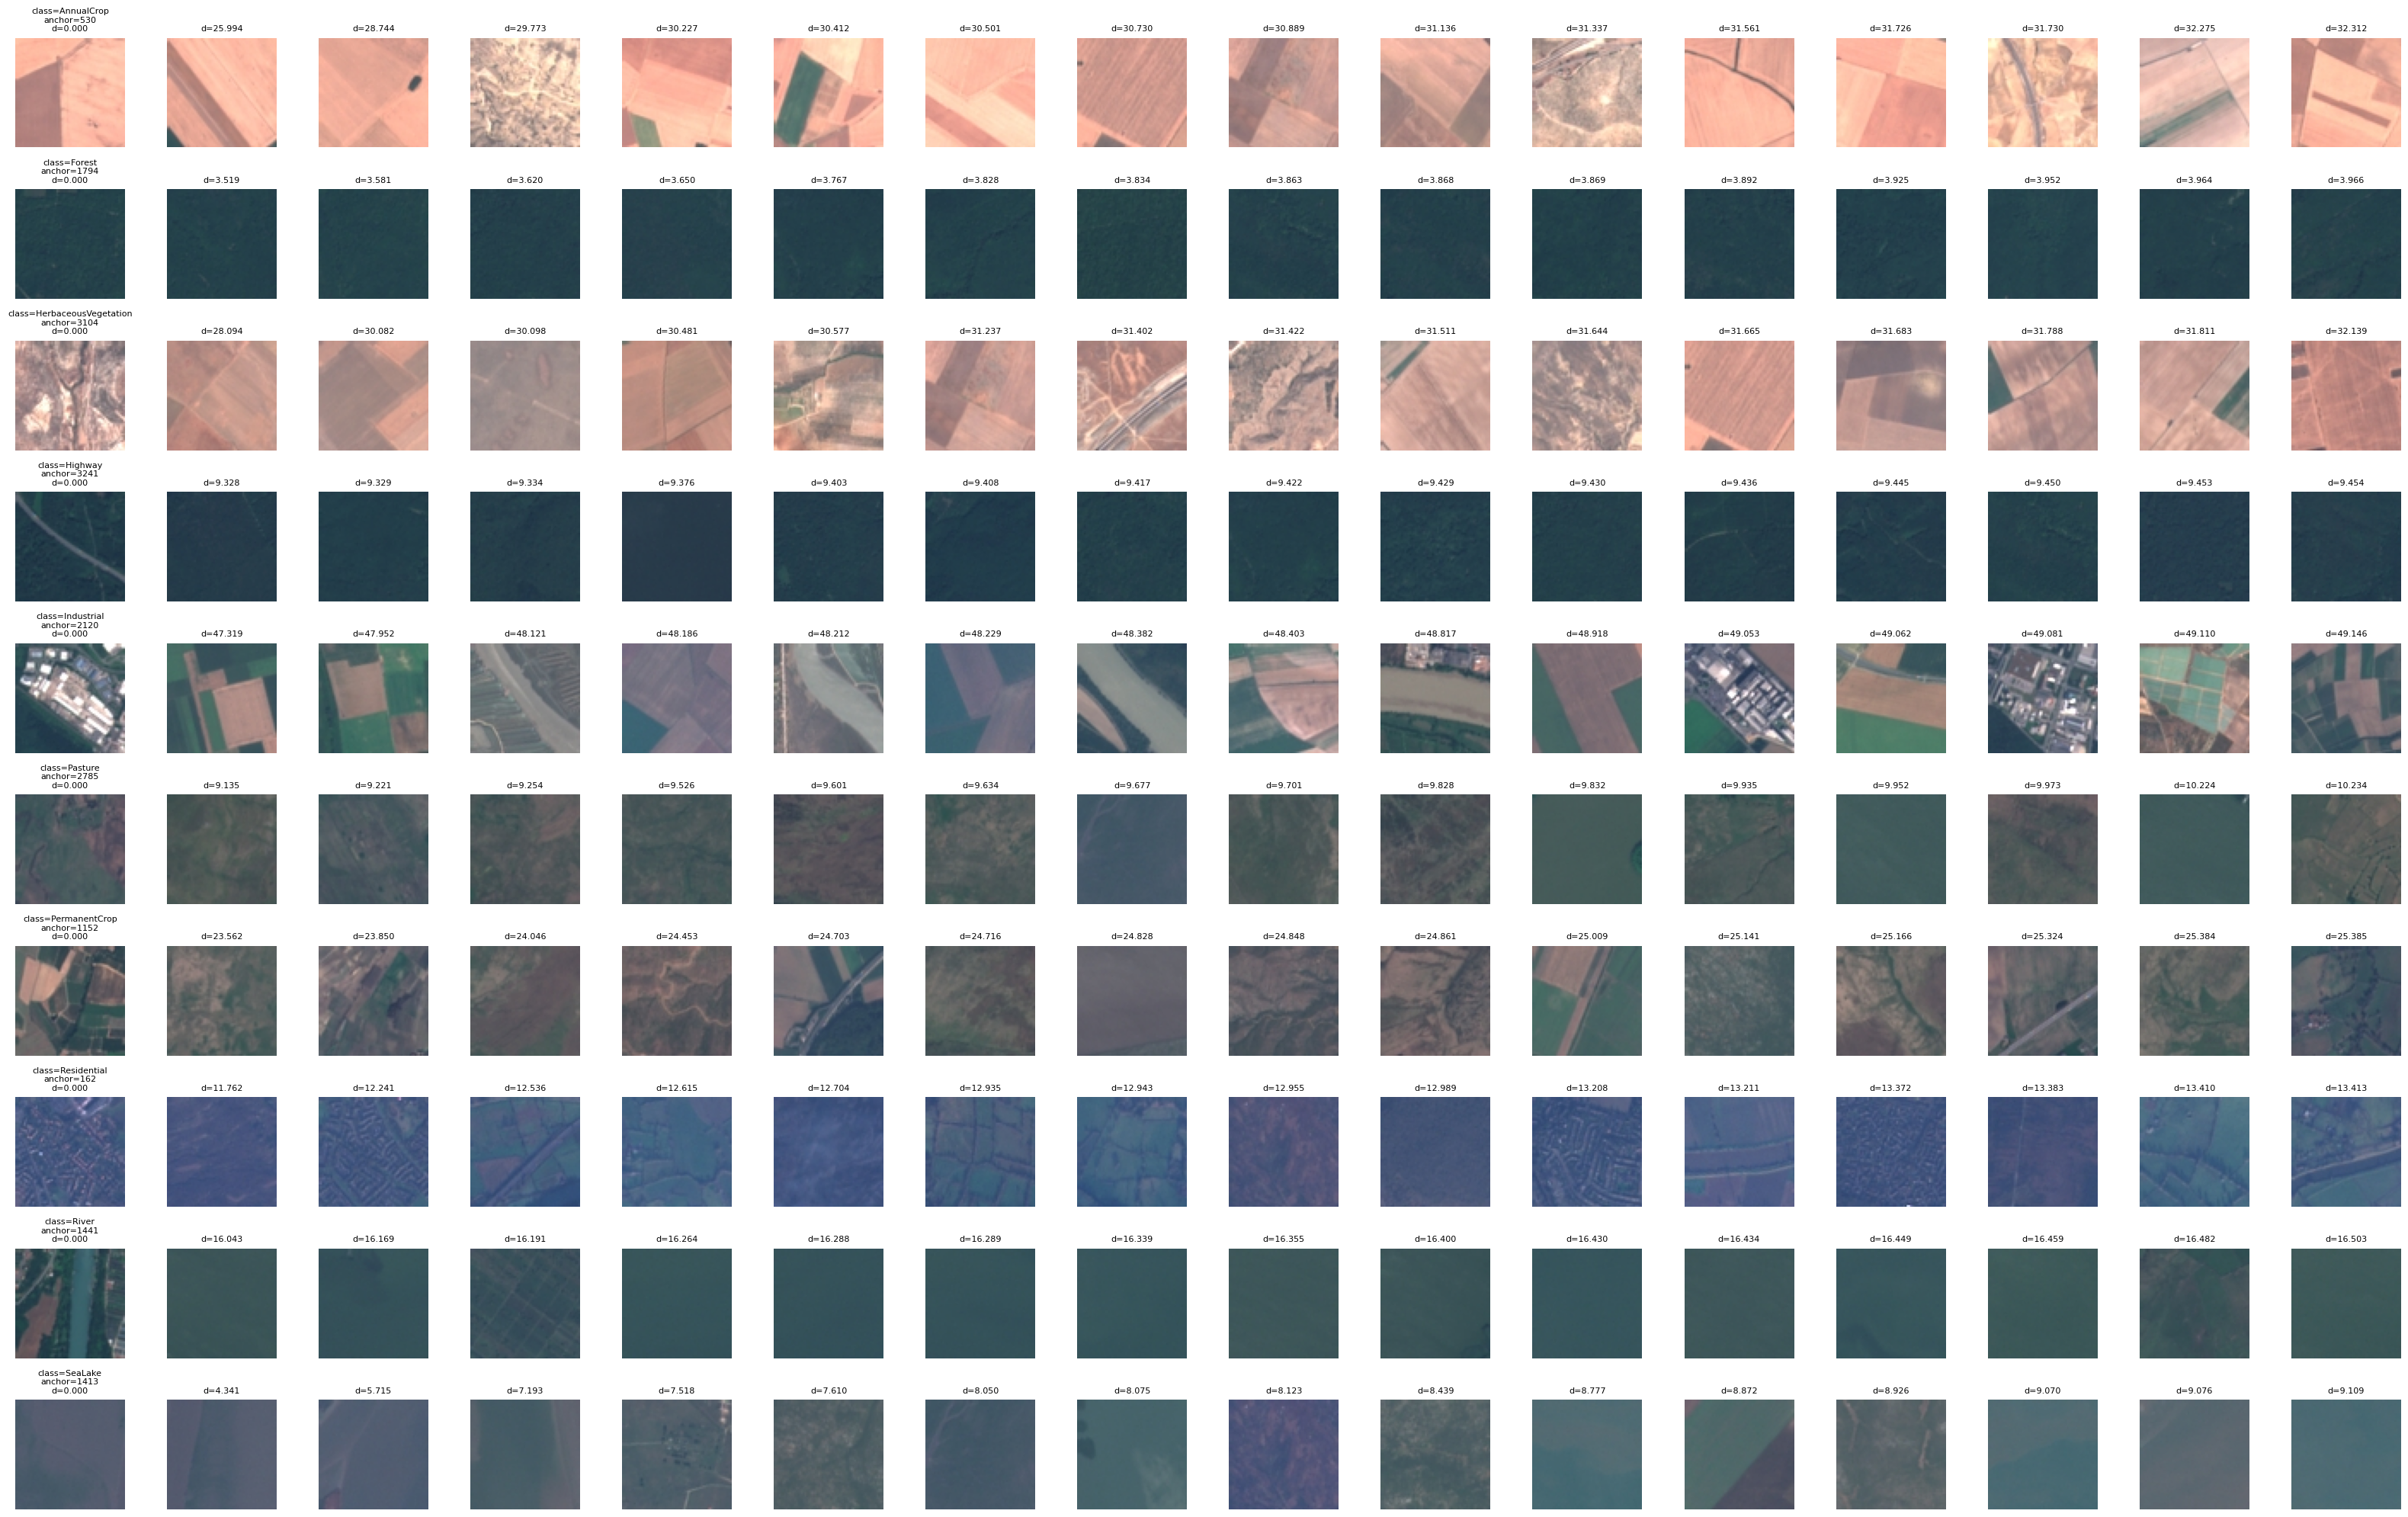

In [21]:
show_class_neighbor_grid(test_images, 
                         indices, 
                         distances, 
                         labels=test_labels, 
                         num_neighbors=15, 
                         classes=classes)

## Plot Wavelet Decomposition


In [22]:
import pywt
import numpy as np

def plot_wavelet_decomposition(img, wavelet='haar'):
    """
    Plot CIFAR-10 RGB image + wavelet decomposition per channel.

    img: (3, 32, 32)
    """
    
    if hasattr(img, "numpy"):
        img = img.numpy()

    channel_names = ['Red', 'Green', 'Blue']

    fig, axes = plt.subplots(3, 5, figsize=(15, 8))

    for c in range(3):

        # --- RGB image ---
        rgb = np.transpose(img, (1, 2, 0))

        axes[c, 0].imshow(rgb)
        axes[c, 0].set_title(f"Original RGB ({channel_names[c]} row)")

        # Add a clear row label on the left side
        axes[c, 0].set_ylabel(
            f"{channel_names[c]} channel",
            rotation=90,
            labelpad=10,
            fontsize=12
        )

        # --- Wavelet transform ---
        LL, (LH, HL, HH) = pywt.dwt2(img[c], wavelet)

        axes[c, 1].imshow(LL, cmap='gray')
        axes[c, 1].set_title(f'LL ({channel_names[c]})')

        axes[c, 2].imshow(LH, cmap='gray')
        axes[c, 2].set_title(f'LH ({channel_names[c]})')

        axes[c, 3].imshow(HL, cmap='gray')
        axes[c, 3].set_title(f'HL ({channel_names[c]})')

        axes[c, 4].imshow(HH, cmap='gray')
        axes[c, 4].set_title(f'HH ({channel_names[c]})')

        for j in range(5):
            axes[c, j].axis('off')

    plt.tight_layout()
    plt.show()

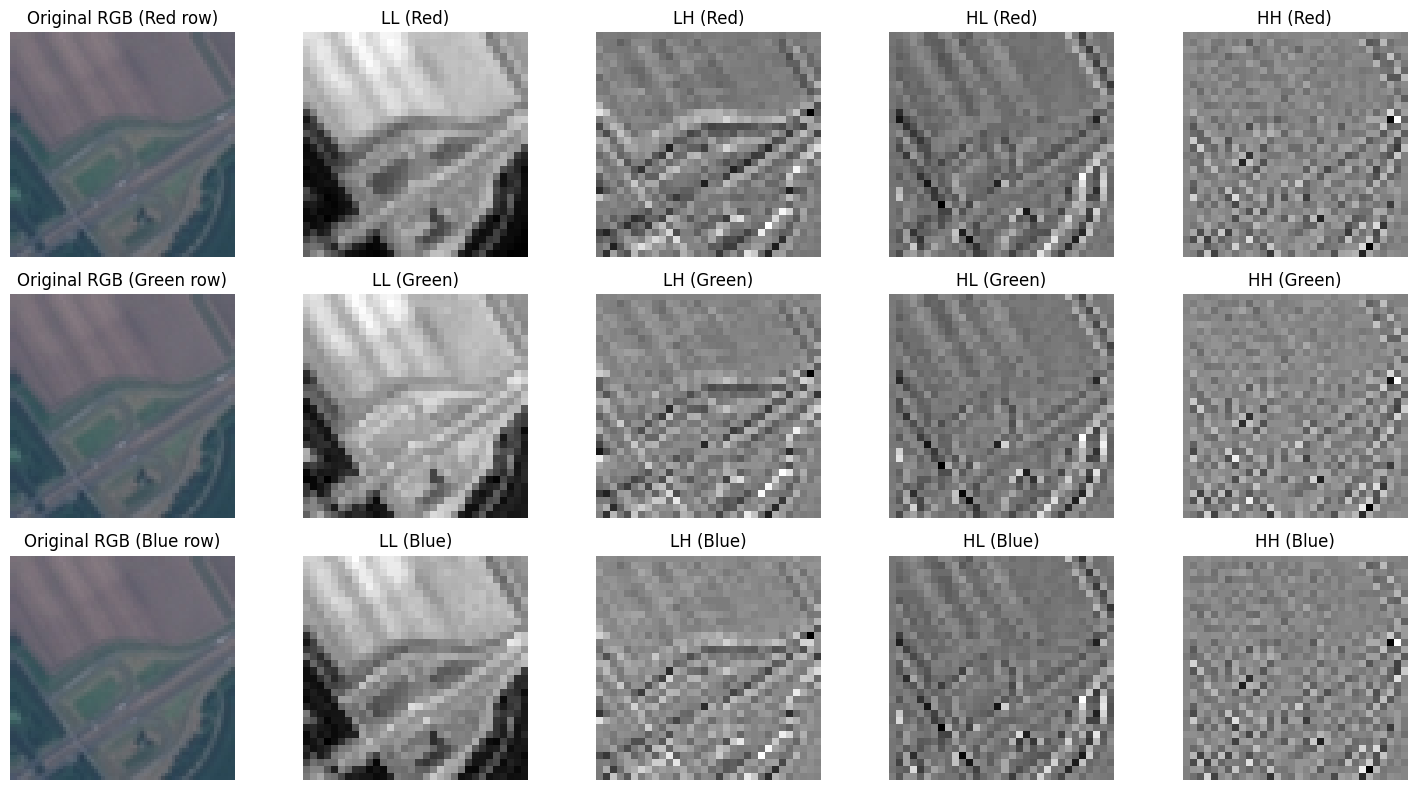

In [23]:
plot_wavelet_decomposition(unnormalize(train_images[42]))

# Average Kernel Size for Random Labels

In [24]:
def add_label_noise(labels, frac, num_classes=10, seed=42):
    rng = np.random.default_rng(seed)
    y = np.array(labels)
    idx = rng.choice(len(y), int(frac * len(y)), replace=False)
    y[idx] = (y[idx] + rng.integers(1, num_classes, len(idx))) % num_classes
    return y, idx

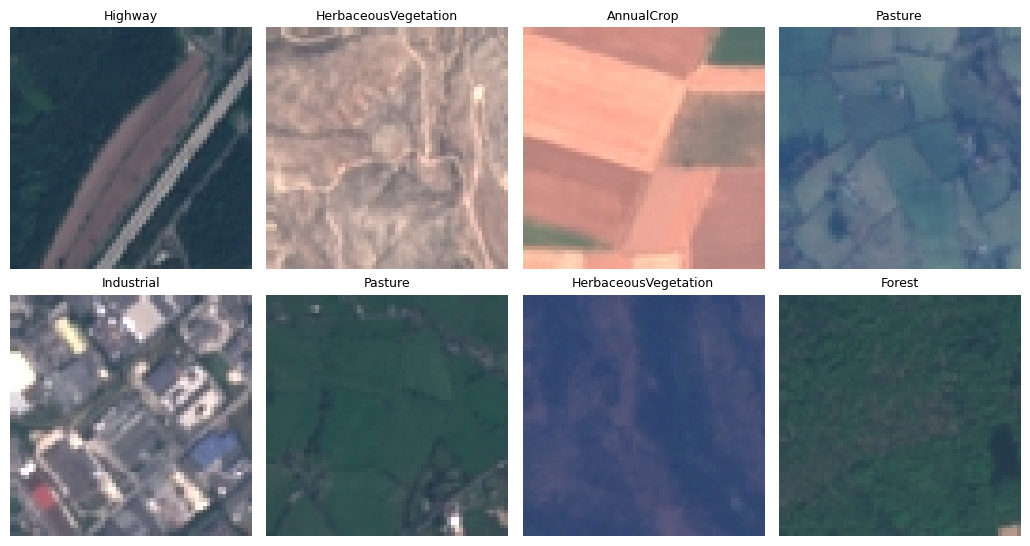

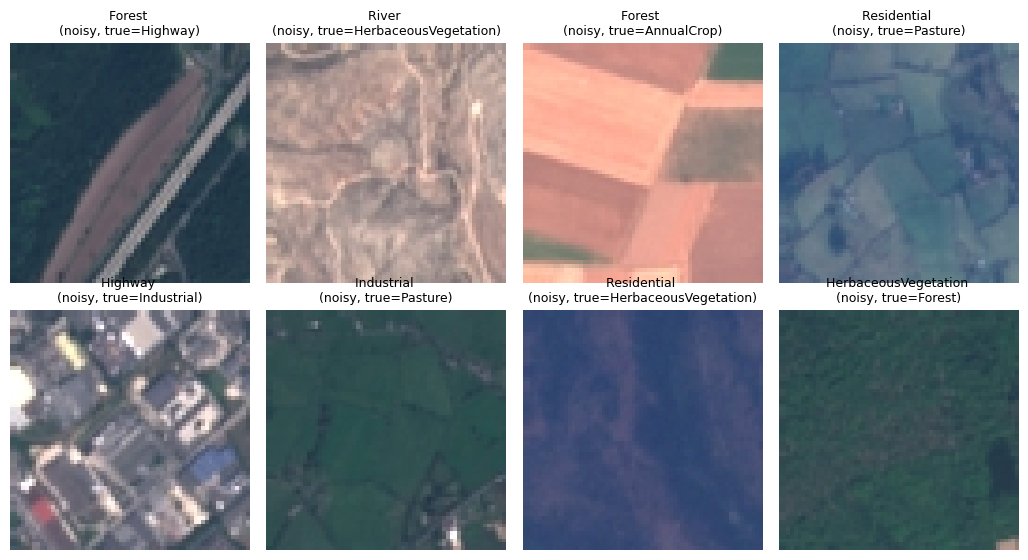

In [25]:
noise_seed = 42

def show_examples(images, labels, clean_labels, n=8, ncols=4, seed=0):
    idx = np.random.default_rng(seed).choice(len(images), n, replace=False)
    fig, axes = plt.subplots(int(np.ceil(n / ncols)), ncols, figsize=(2.6 * ncols, 2.8 * n / ncols), squeeze=False)
    for ax, i in zip(axes.flat, idx):
        ax.imshow(unnormalize(images[i]).transpose([1,2,0]))
        y, y_clean = labels[i], clean_labels[i]
        ax.set_title(f"{classes[y]}" if y == y_clean else f"{classes[y]} \n(noisy, true={classes[y_clean]})", fontsize=9)
    for ax in axes.flat:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

noisy_labels_09, _ = add_label_noise(train_labels, 0.9, seed=noise_seed)
show_examples(train_images, train_labels, train_labels)
show_examples(train_images, noisy_labels_09, train_labels)

In [26]:
noise_seed = 42

train_result_dict_noisy = {}

N_list = sorted([10, 20, 30, 40, 50, 100, 200, 300, 450, 750, 1000, 2000], reverse=True)
qx_list = [0.01, 0.02, 0.03, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
noise_list = [0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

neighbor_stats = None # go though N_max in reverse order to only compute the larges N once

for N_id, N_max in enumerate(N_list):
    train_result_dict_noisy[N_max] ={}

    for noise_id, noise_level in enumerate(noise_list):
        train_result_dict_noisy[N_max][noise_level] = {}

        noisy_labels, _ = add_label_noise(train_labels, noise_level, seed=noise_seed)

        for qx_id, qx in enumerate(qx_list): 
            train_result_dict_noisy[N_max][noise_level][qx] = {"avg_ker_size": None, 
                                                               "tau_x": None,
                                                               "N_k_stats": None}


            print(f"qx [{qx_id+1}/{len(qx_list)}]: {qx}   |   ",\
                  f"Noise [{noise_id+1}/{len(noise_list)}]: {noise_level}   |   ",\
                  f"N_max [{N_id+1}/{len(N_list)}]: {N_max} ...           ", end="\r")
            
            feas = feasible_sets_classification_nn(train_features, noisy_labels, 
                                                N_max=N_max,
                                                qx=qx,
                                                neighbor_stats=neighbor_stats)
            
            tau_x= feas["tau_x"]
            feasible_sets= feas["feasible_sets"]
            D_prime = feas["D_prime"]

            if neighbor_stats is None: 
                neighbor_stats = {"distances": feas["distances"],
                                "indices": feas["indices"]}

            average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(feasible_sets)
            train_result_dict_noisy[N_max][noise_level][qx]["avg_ker_size"] = average_kersize
            train_result_dict_noisy[N_max][noise_level][qx]["tau_x"] = tau_x
            train_result_dict_noisy[N_max][noise_level][qx]["N_k_stats"] = Nk_stats

In [27]:
### Noise Eval
N_max = 200
qx = 0.09
noise_level = 0.2
print("average_kersize on train set: ", train_result_dict_noisy[N_max][noise_level][qx]["avg_ker_size"])
print("Lower accuracy bound:", 1 - train_result_dict_noisy[N_max][noise_level][qx]["avg_ker_size"])
print("Upper accuracy bound:", 1 - 0.5 * train_result_dict_noisy[N_max][noise_level][qx]["avg_ker_size"])
print("tau_x:", train_result_dict_noisy[N_max][noise_level][qx]["tau_x"])
print("Nk:", train_result_dict_noisy[N_max][noise_level][qx]["N_k_stats"])

average_kersize on train set:  0.2900243386697728
Lower accuracy bound: 0.7099756613302273
Upper accuracy bound: 0.8549878306651136
tau_x: 2.4434842586517336
Nk: (1, 5.540123456790123, 1.0, 201)


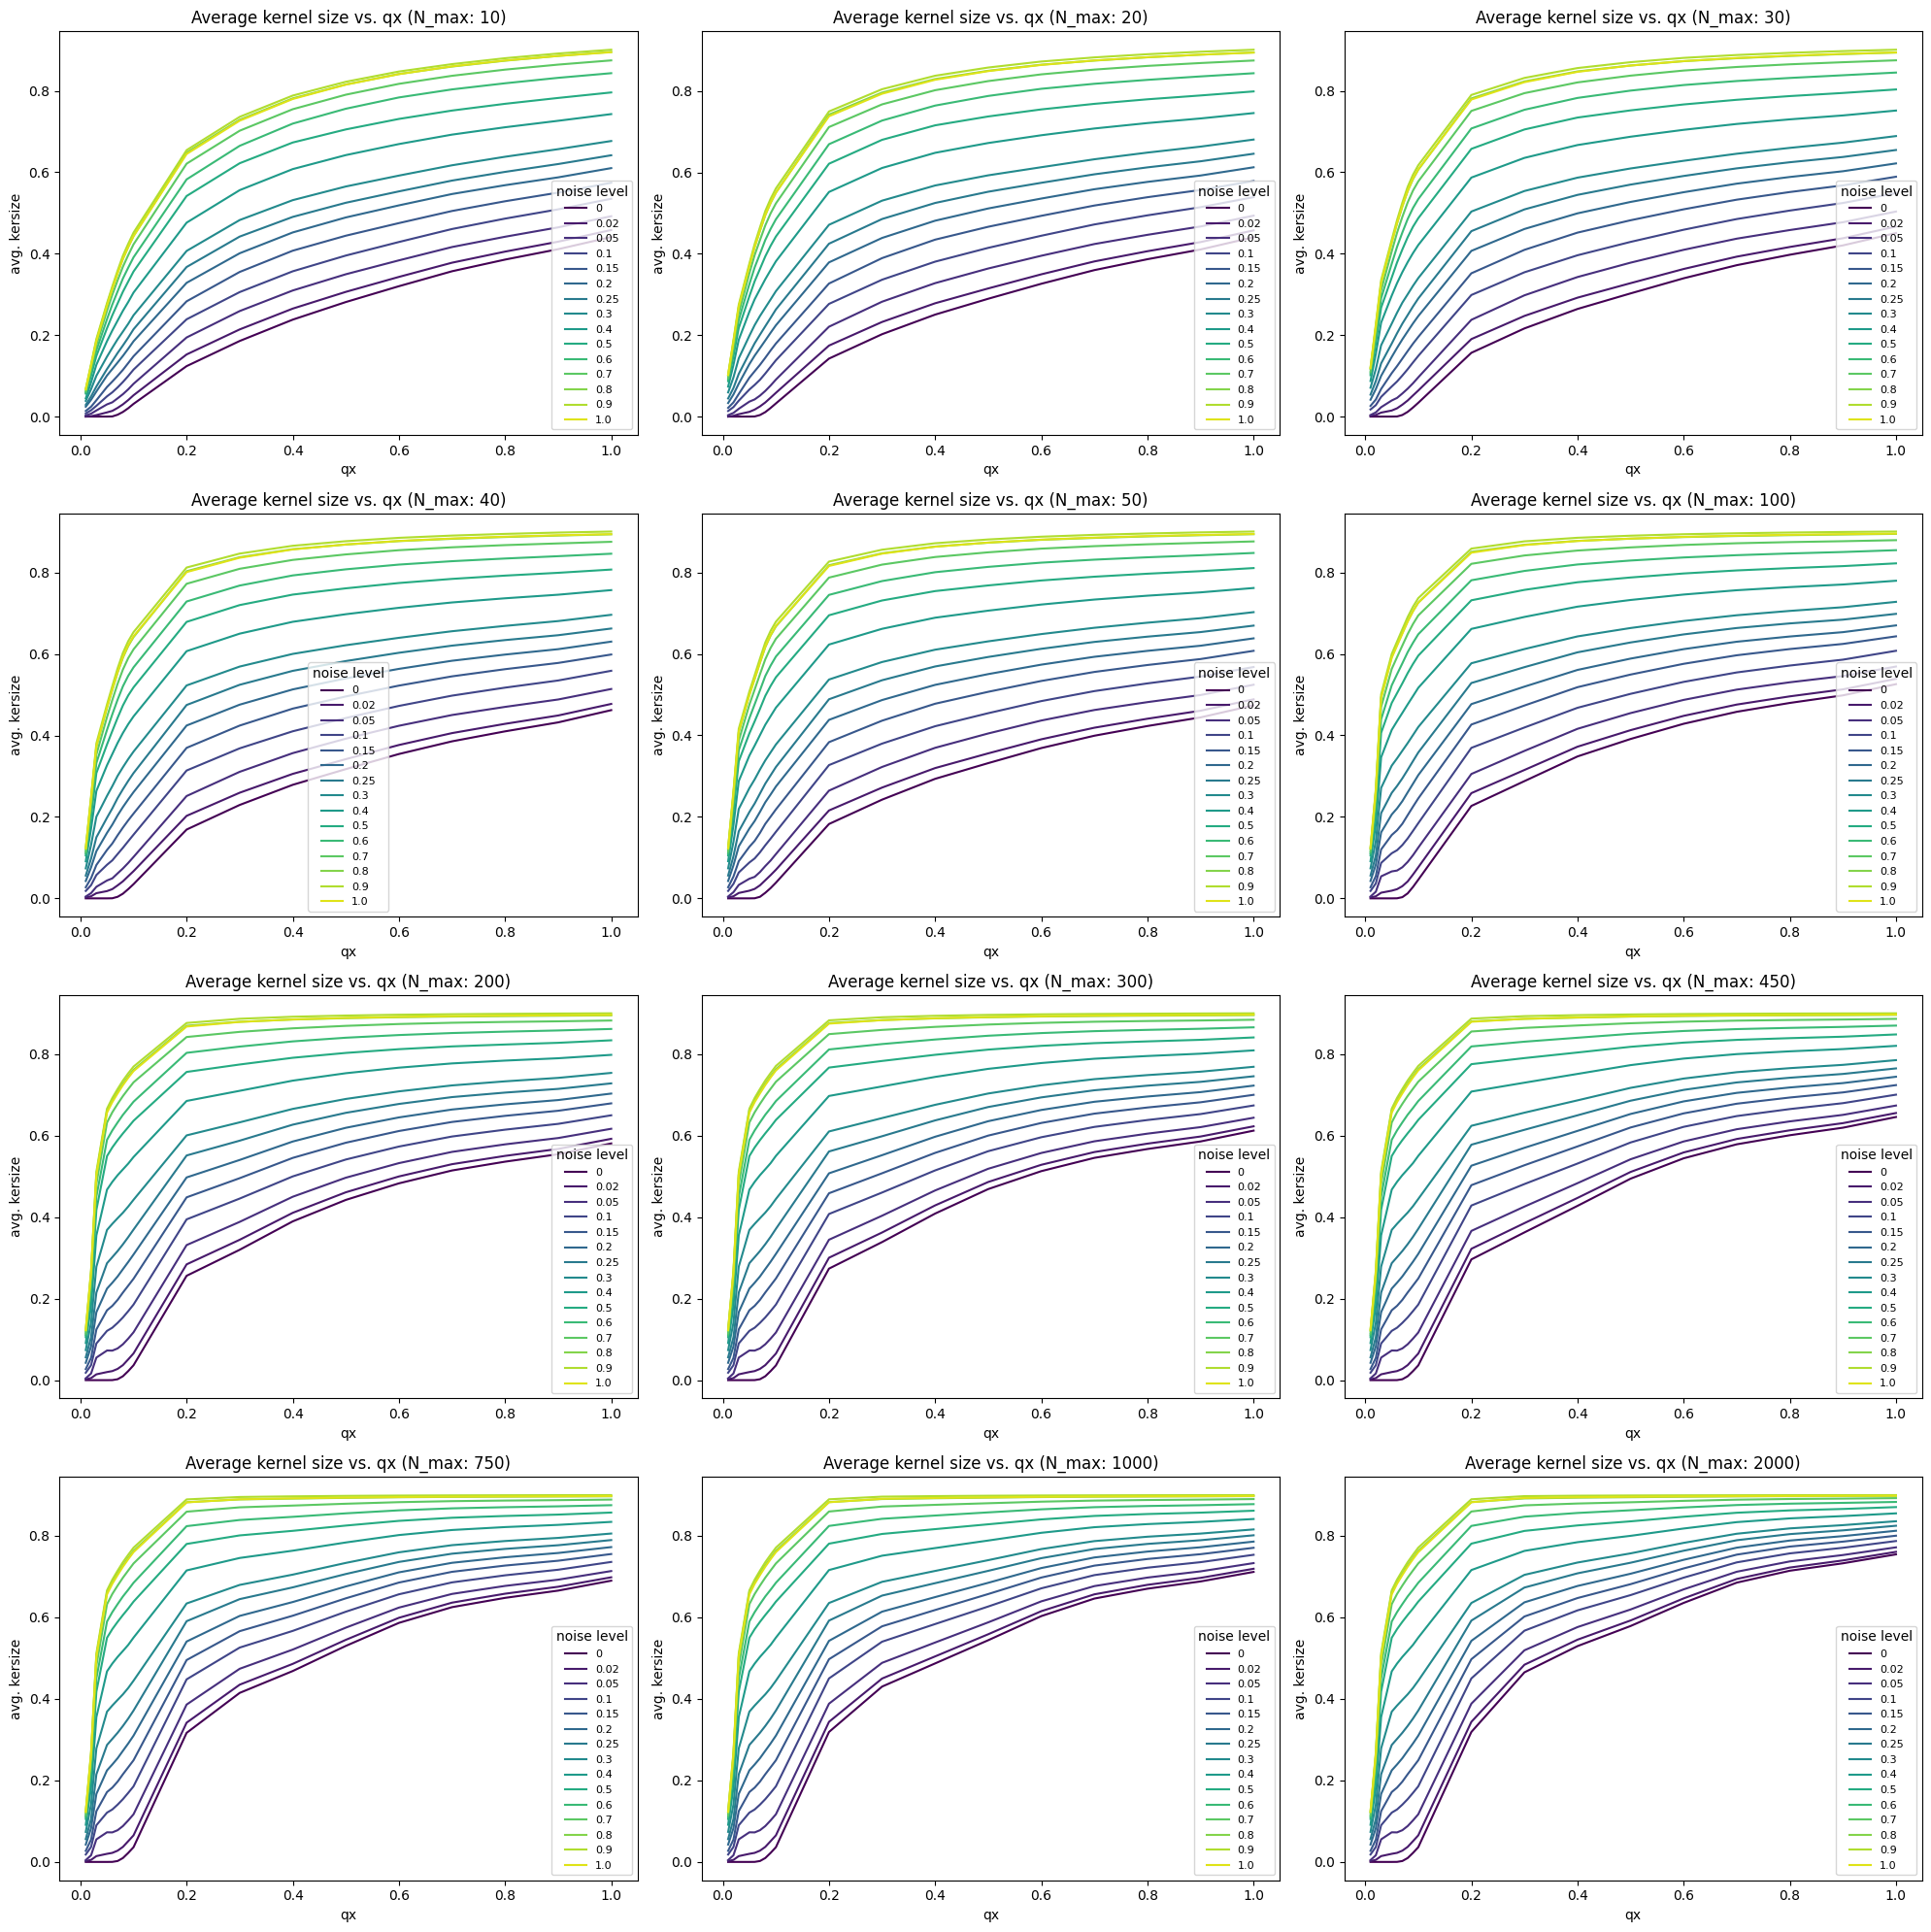

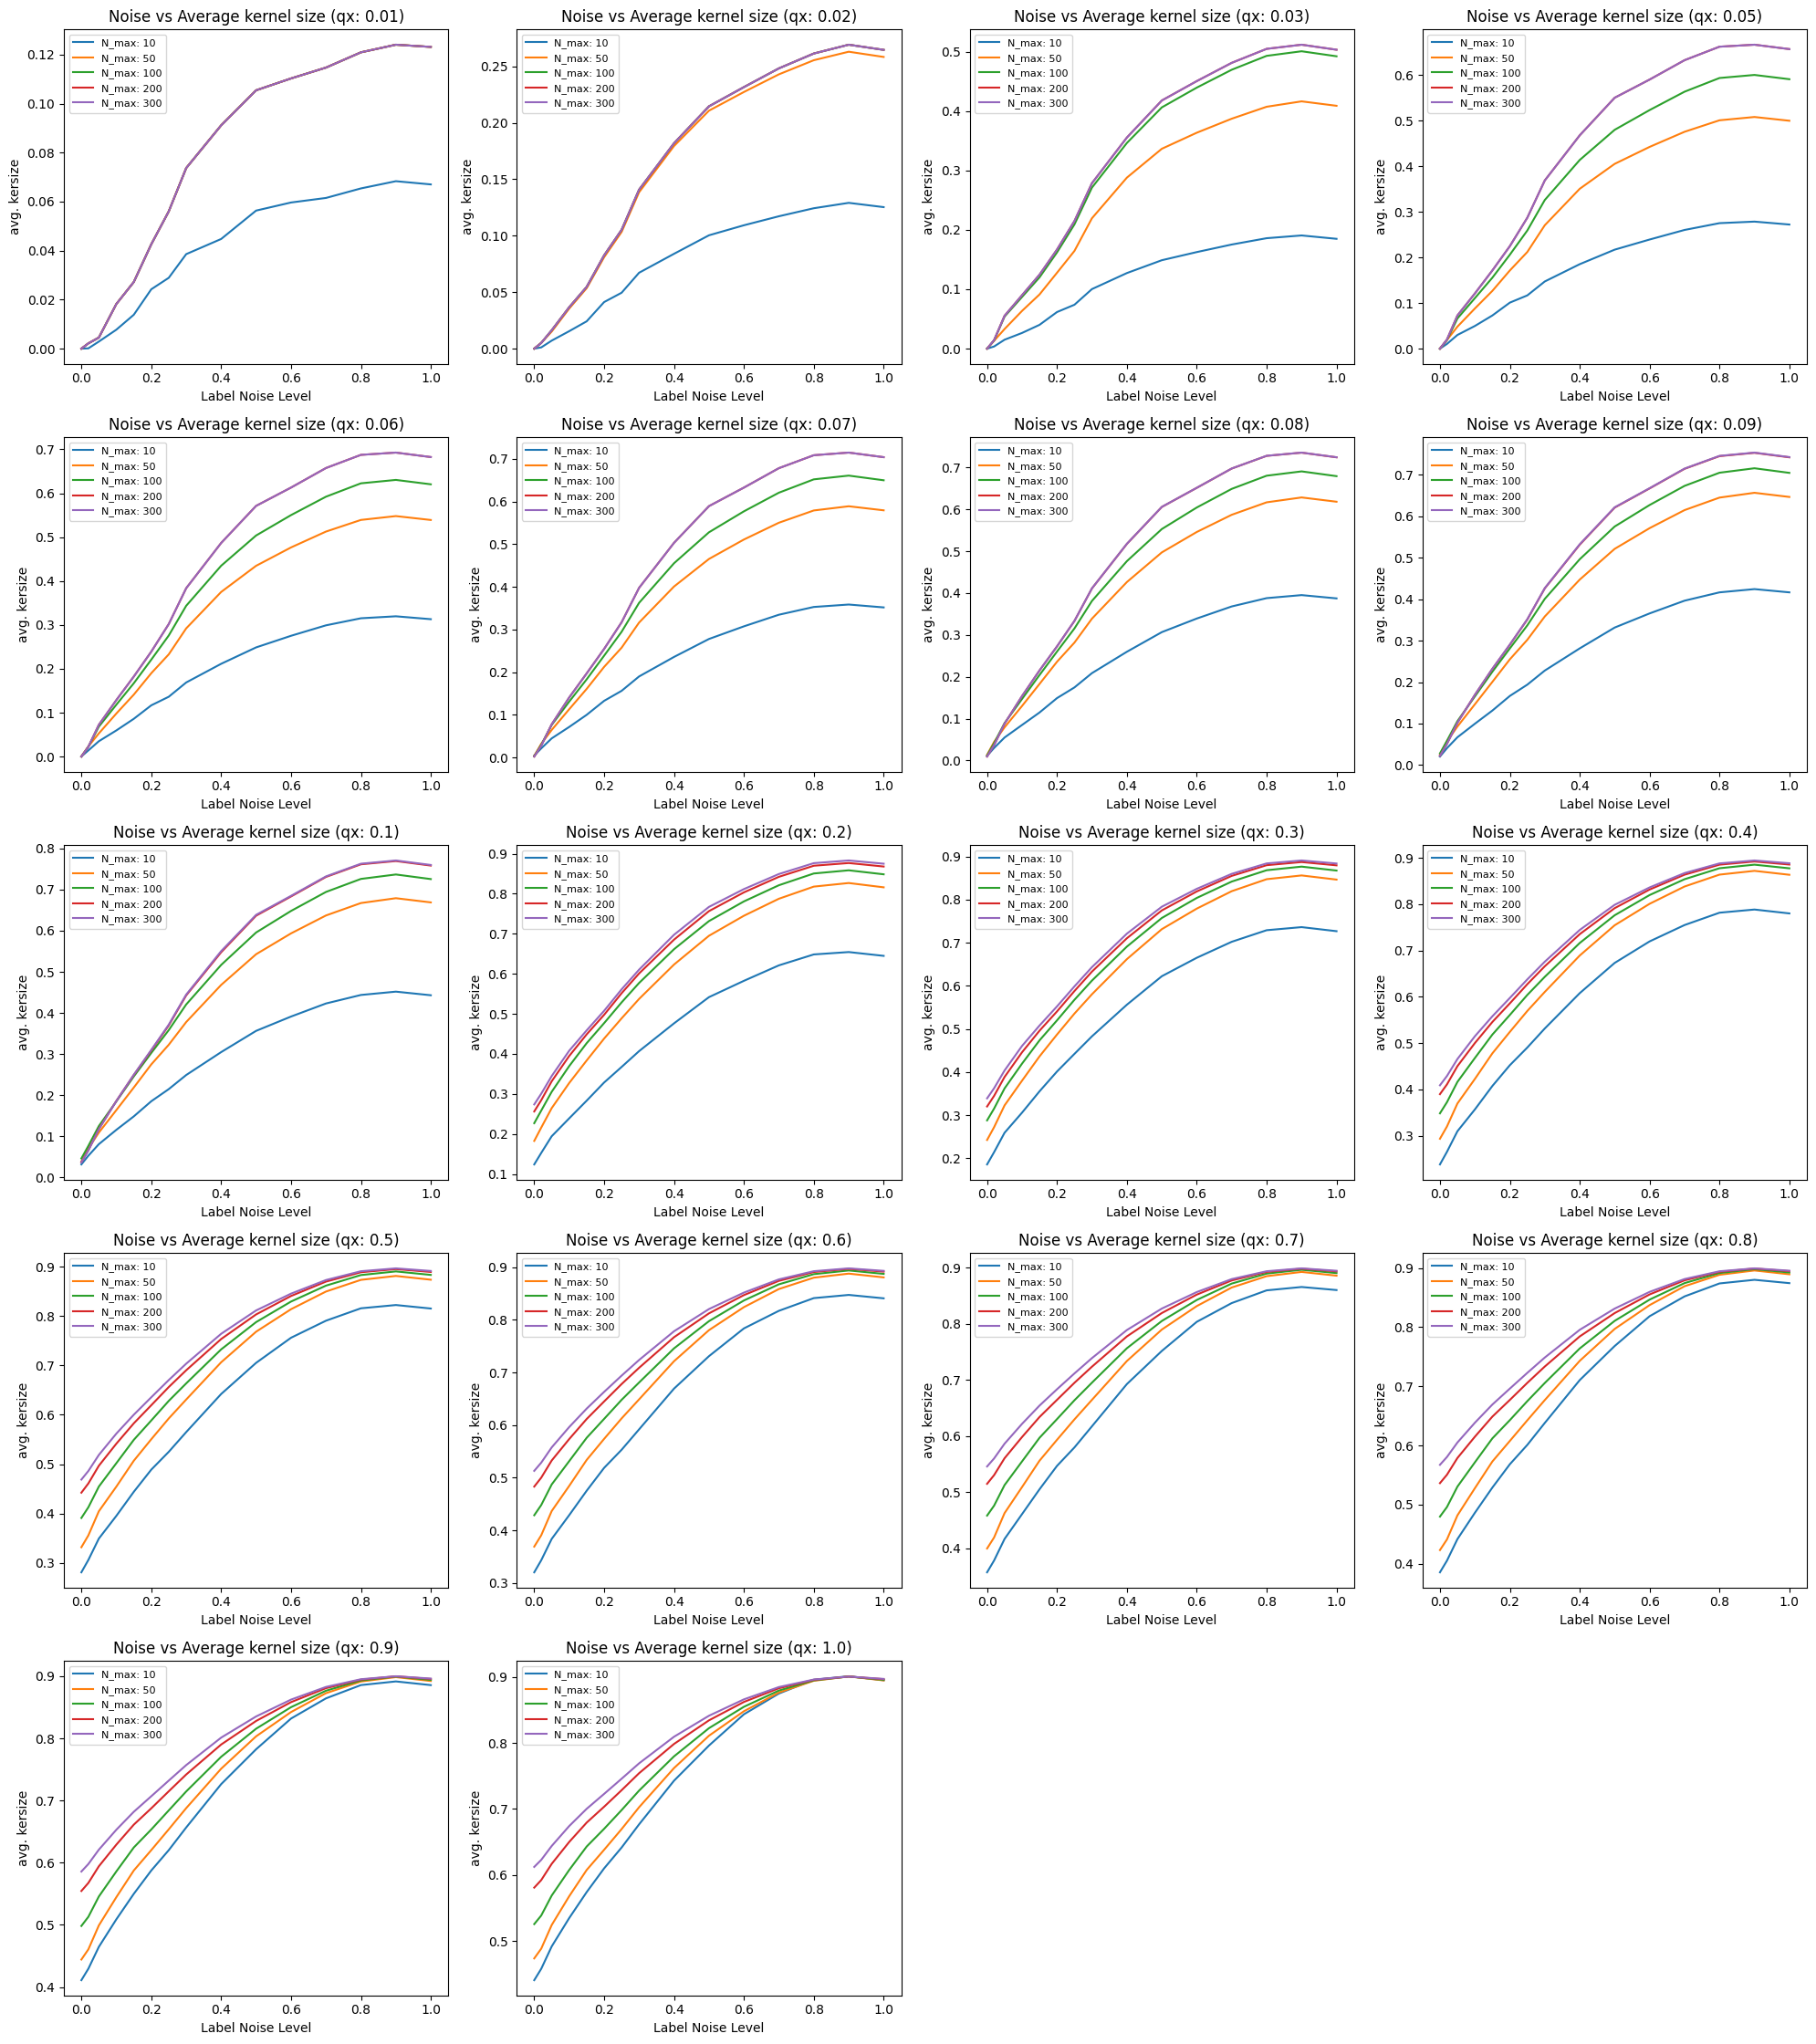

In [28]:
# train_result_dict_noisy[N_max][noise_level][qx]["avg_ker_size"]
res = train_result_dict_noisy
n_max_list = sorted(res)
noise_levels = list(res[n_max_list[0]])
qx_values = list(res[n_max_list[0]][noise_levels[0]])
colors = plt.cm.viridis(np.linspace(0, 0.95, len(noise_levels)))

# --- average kernel size vs. qx: one panel per N_max, one line per noise level ---
num_cols = 3
fig, ax = plt.subplots(int(np.ceil(len(n_max_list) / num_cols)), num_cols,
                       figsize=(20, 5 * int(np.ceil(len(n_max_list) / num_cols))), squeeze=False)
for a, n in zip(ax.flat, n_max_list):
    for noise, c in zip(noise_levels, colors):
        a.plot(qx_values, [res[n][noise][qx]["avg_ker_size"] for qx in qx_values], color=c, label=noise)
    a.set_title(f"Average kernel size vs. qx (N_max: {n})")
    a.set_xlabel("qx")
    a.set_ylabel("avg. kersize")
    a.legend(fontsize=8, title="noise level")
for a in ax.flat[len(n_max_list):]:
    a.axis("off")
plt.tight_layout()
plt.show()

# --- average kernel size vs. noise level: one panel per qx, one line per N_max ---
n_value_list = [10, 50, 100, 200, 300]
num_cols = 4
fig, ax = plt.subplots(int(np.ceil(len(qx_values) / num_cols)), num_cols,
                       figsize=(20, 4.5 * int(np.ceil(len(qx_values) / num_cols))), squeeze=False)
for a, qx in zip(ax.flat, qx_values):
    for n in n_value_list:
        a.plot(noise_levels, [res[n][noise][qx]["avg_ker_size"] for noise in noise_levels], label=f"N_max: {n}")
    a.set_title(f"Noise vs Average kernel size (qx: {qx})")
    a.set_xlabel("Label Noise Level")
    a.set_ylabel("avg. kersize")
    a.legend(fontsize=8)
for a in ax.flat[len(qx_values):]:
    a.axis("off")
plt.tight_layout()
plt.show()

In [29]:
noise_seed = 42

test_result_dict_noisy = {}

N_list = sorted([10, 20, 30, 40, 50, 100, 200, 300, 450, 750, 1000, 2000], reverse=True)
qx_list = [0.01, 0.02, 0.03, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
noise_list = [0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

neighbor_stats = None # go though N_max in reverse order to only compute the larges N once

for N_id, N_max in enumerate(N_list):
    test_result_dict_noisy[N_max] ={}

    for noise_id, noise_level in enumerate(noise_list):
        test_result_dict_noisy[N_max][noise_level] = {}

        noisy_labels, _ = add_label_noise(test_labels, noise_level, seed=noise_seed)

        for qx_id, qx in enumerate(qx_list): 
            test_result_dict_noisy[N_max][noise_level][qx] = {"avg_ker_size": None, 
                                                               "tau_x": None,
                                                               "N_k_stats": None}


            print(f"qx [{qx_id+1}/{len(qx_list)}]: {qx}   |   ",\
                  f"Noise [{noise_id+1}/{len(noise_list)}]: {noise_level}   |   ",\
                  f"N_max [{N_id+1}/{len(N_list)}]: {N_max} ...           ", end="\r")
            
            feas = feasible_sets_classification_nn(test_features, noisy_labels, 
                                                N_max=N_max,
                                                qx=qx,
                                                neighbor_stats=neighbor_stats)
            
            tau_x= feas["tau_x"]
            feasible_sets= feas["feasible_sets"]
            D_prime = feas["D_prime"]

            if neighbor_stats is None: 
                neighbor_stats = {"distances": feas["distances"],
                                "indices": feas["indices"]}

            average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(feasible_sets)
            test_result_dict_noisy[N_max][noise_level][qx]["avg_ker_size"] = average_kersize
            test_result_dict_noisy[N_max][noise_level][qx]["tau_x"] = tau_x
            test_result_dict_noisy[N_max][noise_level][qx]["N_k_stats"] = Nk_stats

In [30]:
### Noise Eval
N_max = 200
qx = 0.09
noise_level = 0.2
print("average_kersize on test set: ", test_result_dict_noisy[N_max][noise_level][qx]["avg_ker_size"])
print("Lower accuracy bound:", 1 - test_result_dict_noisy[N_max][noise_level][qx]["avg_ker_size"])
print("Upper accuracy bound:", 1 - 0.5 * test_result_dict_noisy[N_max][noise_level][qx]["avg_ker_size"])
print("tau_x:", test_result_dict_noisy[N_max][noise_level][qx]["tau_x"])
print("Nk:", test_result_dict_noisy[N_max][noise_level][qx]["N_k_stats"])

average_kersize on test set:  0.26158492899714014
Lower accuracy bound: 0.7384150710028599
Upper accuracy bound: 0.8692075355014299
tau_x: 2.704906494617462
Nk: (1, 2.7733333333333334, 1.0, 92)


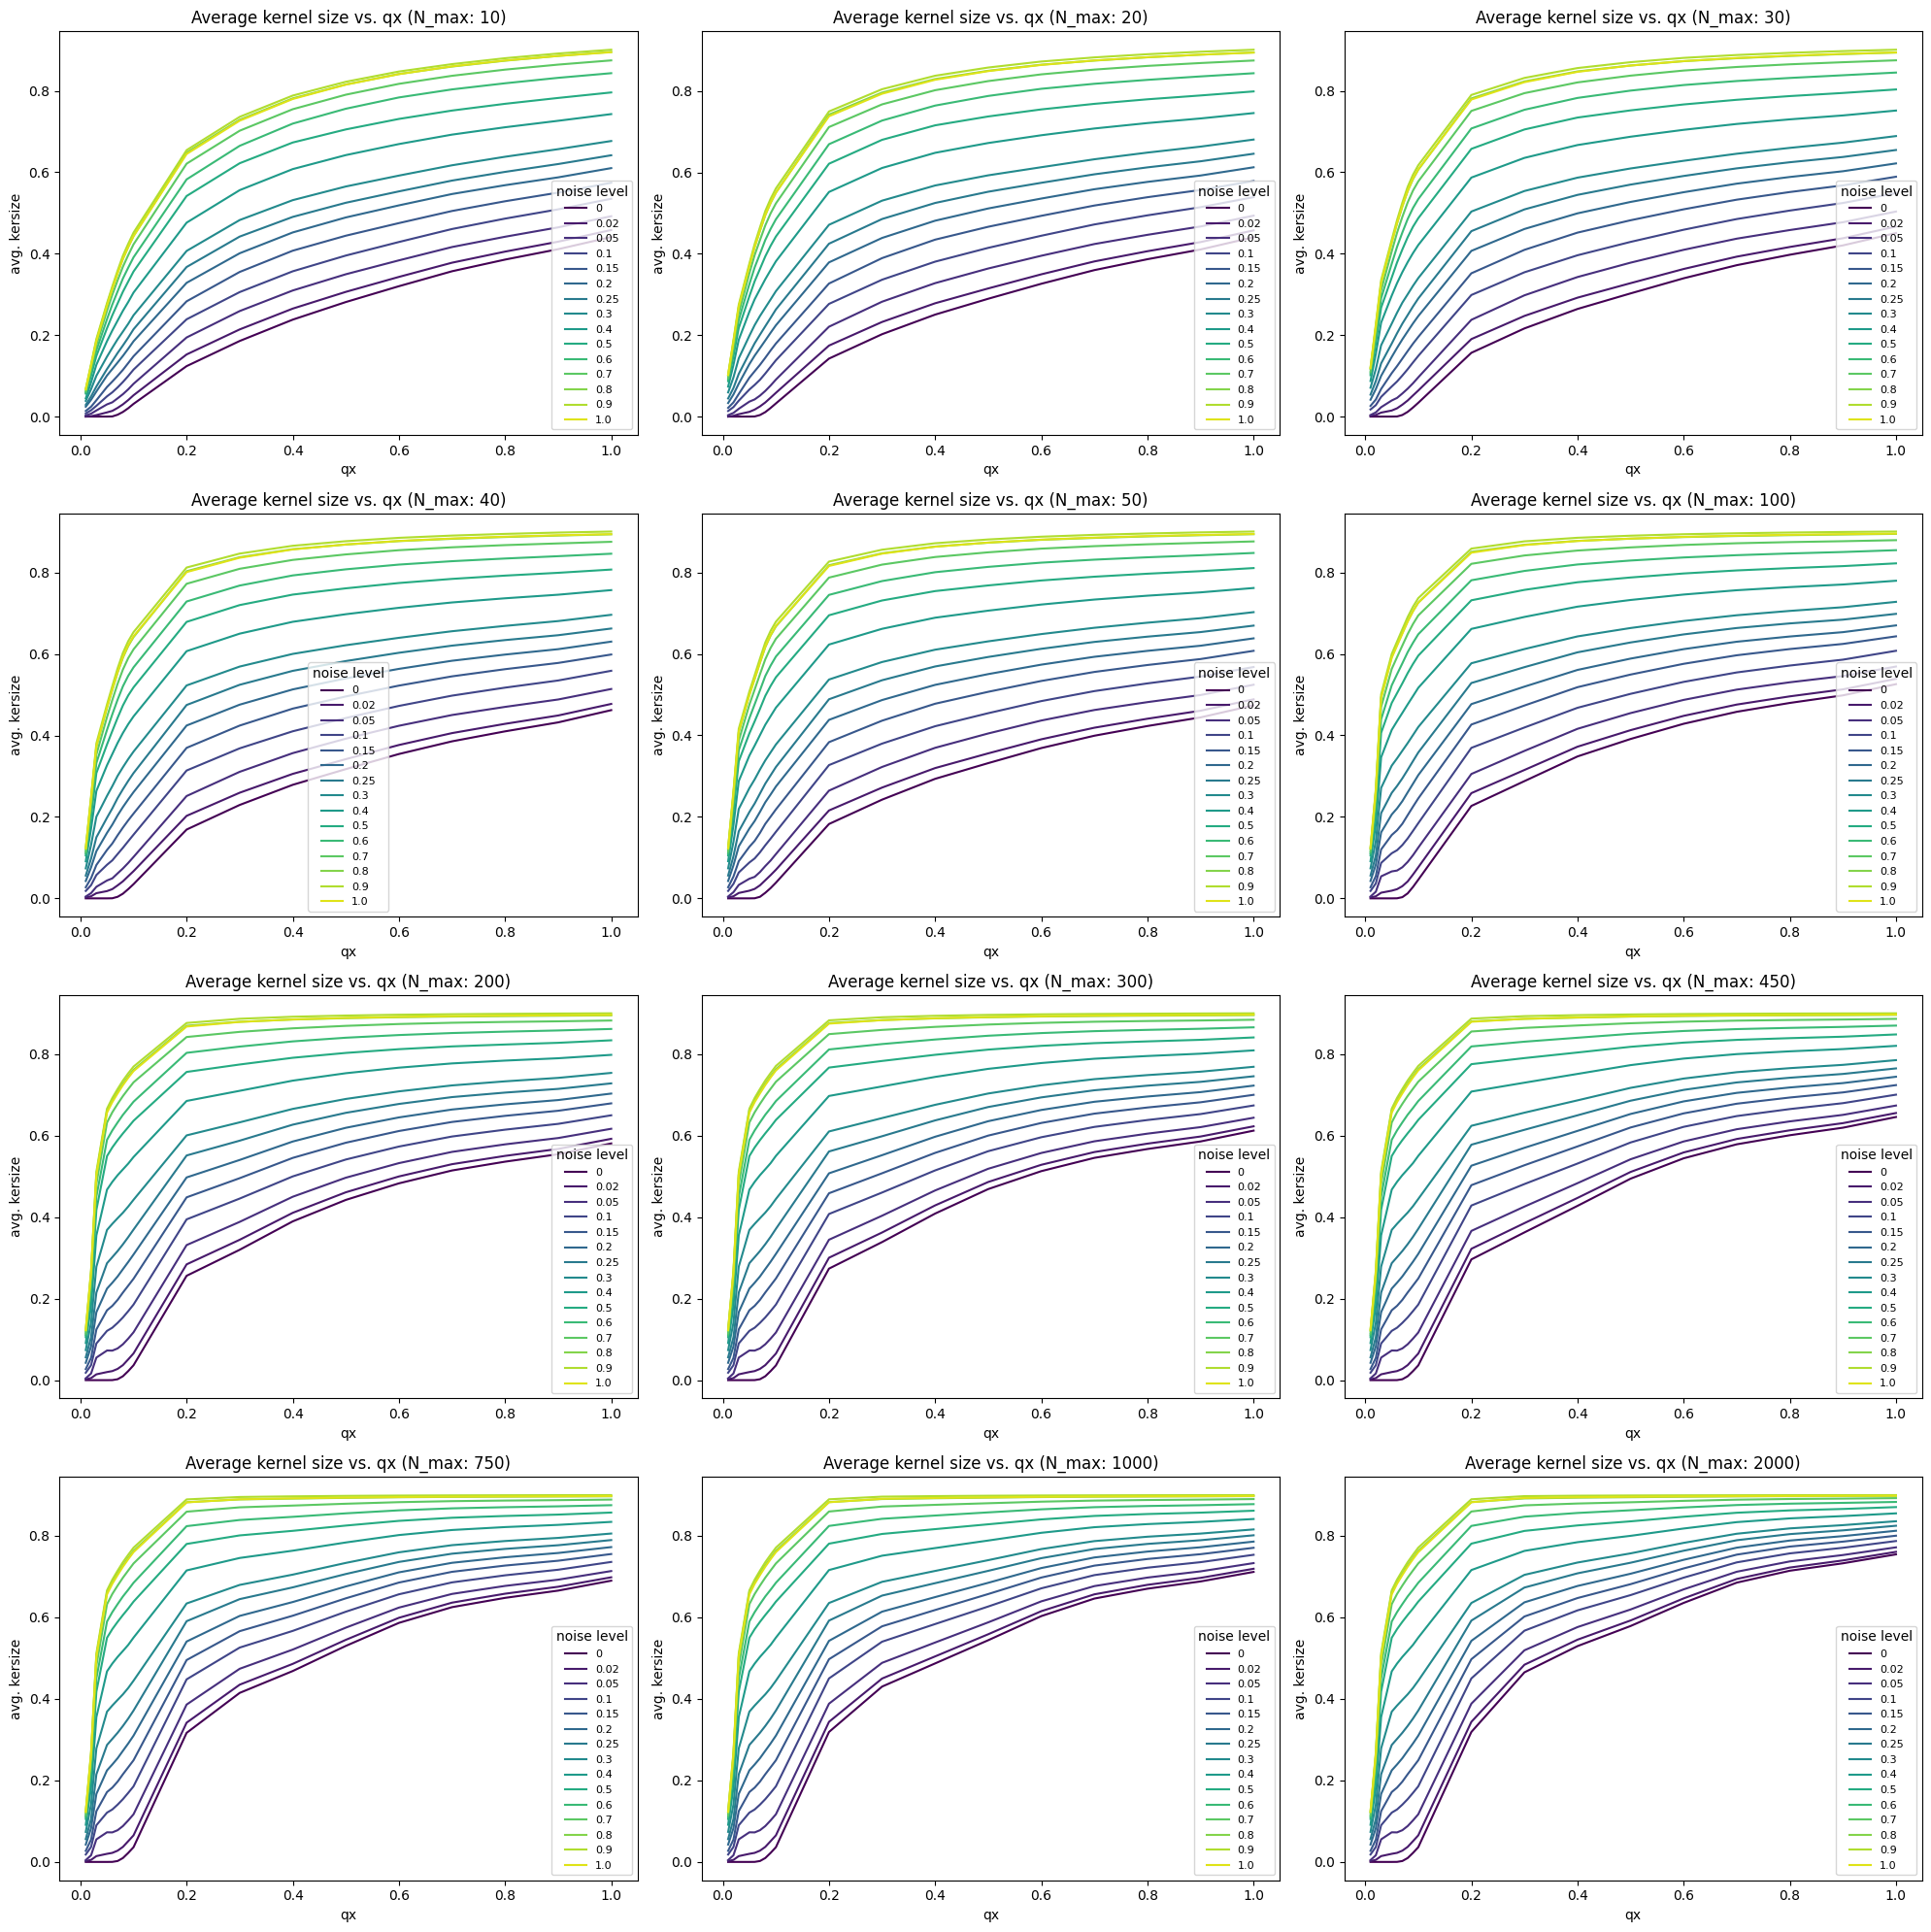

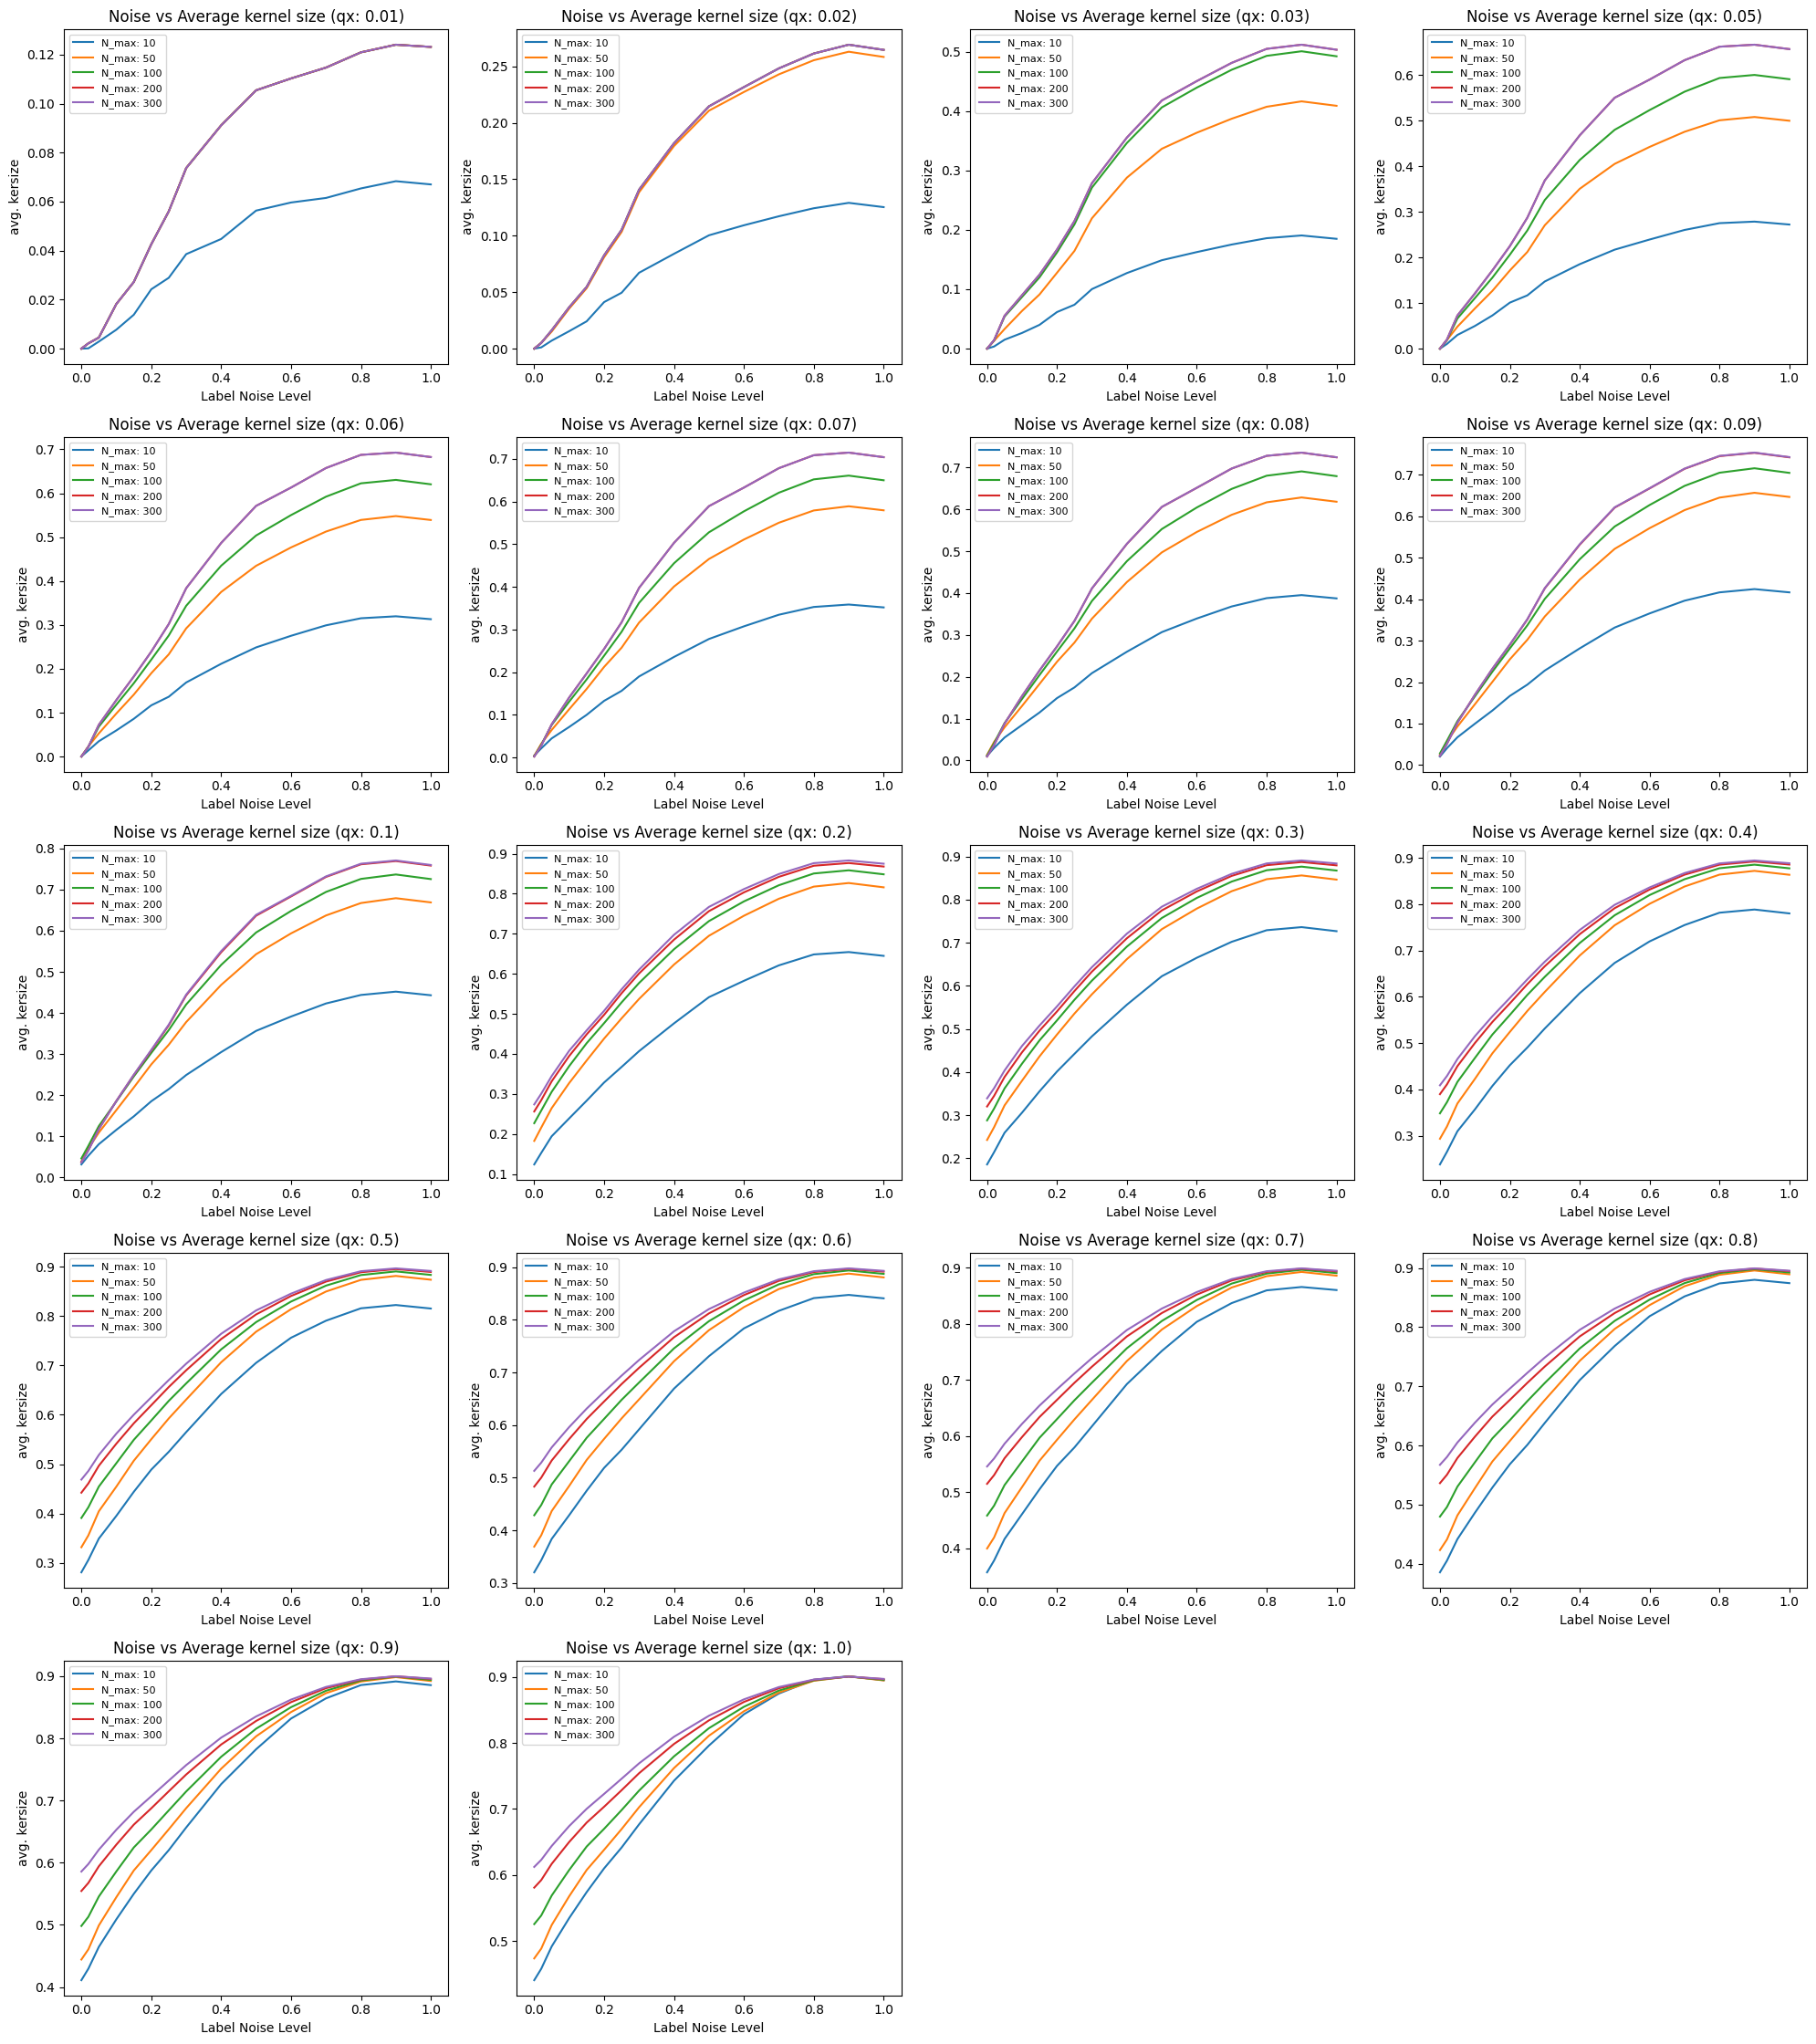

In [31]:
# train_result_dict_noisy[N_max][noise_level][qx]["avg_ker_size"]
res = train_result_dict_noisy
n_max_list = sorted(res)
noise_levels = list(res[n_max_list[0]])
qx_values = list(res[n_max_list[0]][noise_levels[0]])
colors = plt.cm.viridis(np.linspace(0, 0.95, len(noise_levels)))

# --- average kernel size vs. qx: one panel per N_max, one line per noise level ---
num_cols = 3
fig, ax = plt.subplots(int(np.ceil(len(n_max_list) / num_cols)), num_cols,
                       figsize=(20, 5 * int(np.ceil(len(n_max_list) / num_cols))), squeeze=False)
for a, n in zip(ax.flat, n_max_list):
    for noise, c in zip(noise_levels, colors):
        a.plot(qx_values, [res[n][noise][qx]["avg_ker_size"] for qx in qx_values], color=c, label=noise)
    a.set_title(f"Average kernel size vs. qx (N_max: {n})")
    a.set_xlabel("qx")
    a.set_ylabel("avg. kersize")
    a.legend(fontsize=8, title="noise level")
for a in ax.flat[len(n_max_list):]:
    a.axis("off")
plt.tight_layout()
plt.show()

# --- average kernel size vs. noise level: one panel per qx, one line per N_max ---
n_value_list = [10, 50, 100, 200, 300]
num_cols = 4
fig, ax = plt.subplots(int(np.ceil(len(qx_values) / num_cols)), num_cols,
                       figsize=(20, 4.5 * int(np.ceil(len(qx_values) / num_cols))), squeeze=False)
for a, qx in zip(ax.flat, qx_values):
    for n in n_value_list:
        a.plot(noise_levels, [res[n][noise][qx]["avg_ker_size"] for noise in noise_levels], label=f"N_max: {n}")
    a.set_title(f"Noise vs Average kernel size (qx: {qx})")
    a.set_xlabel("Label Noise Level")
    a.set_ylabel("avg. kersize")
    a.legend(fontsize=8)
for a in ax.flat[len(qx_values):]:
    a.axis("off")
plt.tight_layout()
plt.show()